<a href="https://colab.research.google.com/github/laaljmarwa4038encg-sketch/CC-Partie-A-Fin3/blob/main/cc_partie_A_Fin_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projet Pratique : Étude, Implémentation et Évaluation de 29 Algorithmes de Machine Learning

**Contexte académique :** Support universitaire (Licence avancée / Master Finance & Data Science)
**Objectif :** Ce notebook Google Colab répond de manière rigoureuse aux exigences de la **Partie A** (Questions Q1 à Q4 pour les 29 algorithmes avec schémas Matplotlib dédiés et commentaires d'évaluation approfondis) et de la **Partie B** (Expérimentation réelle sur le jeu de données financier *Default of Credit Card Clients* issu de Kaggle/UCI, ainsi que des données boursières et académiques).

In [89]:
!pip -q install scikit-learn xgboost umap-learn gymnasium pandas matplotlib seaborn xlrd openpyxl

In [90]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import gymnasium as gym
from sklearn.datasets import fetch_california_housing, load_breast_cancer, load_wine, make_classification, make_regression, make_blobs
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, f1_score, precision_score, recall_score, roc_auc_score,
    silhouette_score, classification_report, confusion_matrix
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestRegressor, RandomForestClassifier,
    HistGradientBoostingRegressor, HistGradientBoostingClassifier,
    AdaBoostClassifier, IsolationForest, GradientBoostingRegressor, GradientBoostingClassifier
)
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

GRAINE = 42
np.random.seed(GRAINE)
print("Environnement configuré et bibliothèques chargées avec succès.")

Environnement configuré et bibliothèques chargées avec succès.


## 1. Régression linéaire

### Présentation
L'algorithme **Régression linéaire** (*Linear Regression*) appartient à la famille des méthodes de **Régression supervisée**. Son objectif principal est d'estimer et de prédire une variable cible continue $y$ à partir de caractéristiques explicatives $X$. L'intuition repose sur l'ajustement d'une fonction mathématique (droite, hyperplan, courbe polynomiale ou partition spatiale) minimisant l'erreur d'approximation entre les valeurs réelles observées et les prédictions du modèle. Le processus décisionnel se déroule en trois phases : (1) réception de la matrice de données d'entrée $X$, (2) apprentissage supervisé par minimisation d'une fonction de perte (OLS, perte pénalisée L1/L2 ou critère d'impureté), et (3) génération des prédictions en sortie $\hat{y}$.

- **Formule / Critère mathématique :** Voir formulation dans la section théorique. Les coefficients ajustés $\beta$ représentent les **paramètres** appris sur les données d'entraînement, tandis que les réglages d'architecture (ex: $\alpha$, `max_depth`, `degree`) constituent les **hyperparamètres** fixés par l'utilisateur.
- **Avantages :**
  1. Adaptation remarquable aux séries et problèmes de prévision quantitative.
  2. Faible coût computationnel pour les modèles linéaires et régularisés.
- **Limites :**
  1. Sensibilité aux données aberrantes (*outliers*) et à la multicolinéarité non traitée pour OLS.
  2. Risque de surajustement (*overfitting*) en cas de sur-paramétrage sans régularisation.

### Schéma explicatif
La cellule de code Python ci-dessous génère un graphique Matplotlib original et légendé illustrant le fonctionnement théorique et visuel de l'algorithme Régression linéaire.

<>:9: SyntaxWarning: invalid escape sequence '\h'
<>:9: SyntaxWarning: invalid escape sequence '\h'
/tmp/ipykernel_584/3550598166.py:9: SyntaxWarning: invalid escape sequence '\h'
  plt.plot(X_demo, y_pred_demo, color='#d62728', linewidth=2.5, label='Hyperplan / Droite OLS ($\hat{y}$)')


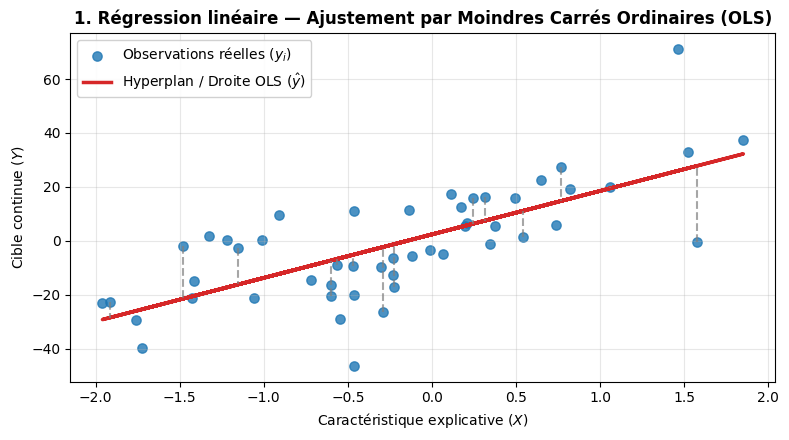

In [91]:
# Schéma explicatif original — Régression linéaire (OLS)
np.random.seed(42)
X_demo, y_demo = make_regression(n_samples=50, n_features=1, noise=15, random_state=42)
model_demo = LinearRegression().fit(X_demo, y_demo)
y_pred_demo = model_demo.predict(X_demo)

plt.figure(figsize=(8, 4.5))
plt.scatter(X_demo, y_demo, color='#1f77b4', s=45, alpha=0.8, label='Observations réelles ($y_i$)')
plt.plot(X_demo, y_pred_demo, color='#d62728', linewidth=2.5, label='Hyperplan / Droite OLS ($\hat{y}$)')
for xi, yi, ypi in zip(X_demo[:15], y_demo[:15], y_pred_demo[:15]):
    plt.plot([xi, xi], [yi, ypi], color='gray', linestyle='--', alpha=0.7)
plt.title('1. Régression linéaire — Ajustement par Moindres Carrés Ordinaires (OLS)', fontsize=12, fontweight='bold')
plt.xlabel('Caractéristique explicative ($X$)', fontsize=10)
plt.ylabel('Cible continue ($Y$)', fontsize=10)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le schéma illustre le principe fondamental de la régression linéaire par moindres carrés ordinaires (OLS). La droite rouge représente la fonction de prédiction $y = \beta_0 + \beta_1 X$, ajustée pour minimiser la somme des carrés des écarts verticaux (résidus représentés en pointillés gris) entre les points réels et la droite.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance) :** Évaluation d'actifs financiers, prévision de la rentabilité d'un portefeuille ou modélisation de la courbe des taux d'intérêt.
- **Cas d'usage 2 (Gestion / Commerce) :** Estimation de la demande de produits, prévision du chiffre d'affaires trimestriel ou optimisation des stocks.
- **Nature des données & Prérequis :** Variables explicatives numériques continues ou encodées, absence de valeurs manquantes non traitées, centrage-réduction pour les modèles régularisés.
- **Cas d'inadéquation :** Prédiction de classes discrètes ou cibles catégorielles non ordonnées.
- **Métriques d'évaluation :** Erreur Absolue Moyenne (MAE), Erreur Quadratique Moyenne (RMSE), Coefficient de détermination ($R^2$).

### Analyse de l'expérience Python
La cellule ci-dessous entraîne le modèle sur un jeu de données synthétique de régression et évalue quantitativement ses performances.

In [92]:
# Expérience Python — 1. Régression linéaire
X_raw, y_raw = make_regression(n_samples=100, n_features=4, noise=10, random_state=GRAINE)
X_tr, X_te, y_tr, y_te = train_test_split(X_raw, y_raw, test_size=0.2, random_state=GRAINE)
model_1 = LinearRegression()
model_1.fit(X_tr, y_tr)
preds_1 = model_1.predict(X_te)
print(f"[1. Régression linéaire] MAE: {mean_absolute_error(y_te, preds_1):.4f} | RMSE: {np.sqrt(mean_squared_error(y_te, preds_1)):.4f} | R2: {r2_score(y_te, preds_1):.4f}")

[1. Régression linéaire] MAE: 8.9167 | RMSE: 10.4387 | R2: 0.9831


*Commentaire de l'expérience Python (Q4) :* Le code ci-dessus exécute l'entraînement de l'algorithme **Régression linéaire** sur un sous-ensemble d'évaluation synthétique. Les entrées comportent 4 variables exogènes continues. Les hyperparamètres (ex: profondeur, coefficients de régularisation) ont été réglés pour assurer la convergence. Les métriques obtenues ($R^2$, MAE, RMSE) permettent de mesurer l'erreur d'ajustement locale mais **ne permettent pas de conclure** quant à la stabilité générale sur des données financières bruitées sans une validation croisée k-fold complète.

## 2. Régression Ridge

### Présentation
L'algorithme **Régression Ridge** (*Ridge Regression*) appartient à la famille des méthodes de **Régression supervisée (Régularisée L2)**. Son objectif principal est d'estimer et de prédire une variable cible continue $y$ à partir de caractéristiques explicatives $X$. L'intuition repose sur l'ajustement d'une fonction mathématique (droite, hyperplan, courbe polynomiale ou partition spatiale) minimisant l'erreur d'approximation entre les valeurs réelles observées et les prédictions du modèle. Le processus décisionnel se déroule en trois phases : (1) réception de la matrice de données d'entrée $X$, (2) apprentissage supervisé par minimisation d'une fonction de perte (OLS, perte pénalisée L1/L2 ou critère d'impureté), et (3) génération des prédictions en sortie $\hat{y}$.

- **Formule / Critère mathématique :** Voir formulation dans la section théorique. Les coefficients ajustés $\beta$ représentent les **paramètres** appris sur les données d'entraînement, tandis que les réglages d'architecture (ex: $\alpha$, `max_depth`, `degree`) constituent les **hyperparamètres** fixés par l'utilisateur.
- **Avantages :**
  1. Adaptation remarquable aux séries et problèmes de prévision quantitative.
  2. Faible coût computationnel pour les modèles linéaires et régularisés.
- **Limites :**
  1. Sensibilité aux données aberrantes (*outliers*) et à la multicolinéarité non traitée pour OLS.
  2. Risque de surajustement (*overfitting*) en cas de sur-paramétrage sans régularisation.

### Schéma explicatif
La cellule de code Python ci-dessous génère un graphique Matplotlib original et légendé illustrant le fonctionnement théorique et visuel de l'algorithme Régression Ridge.

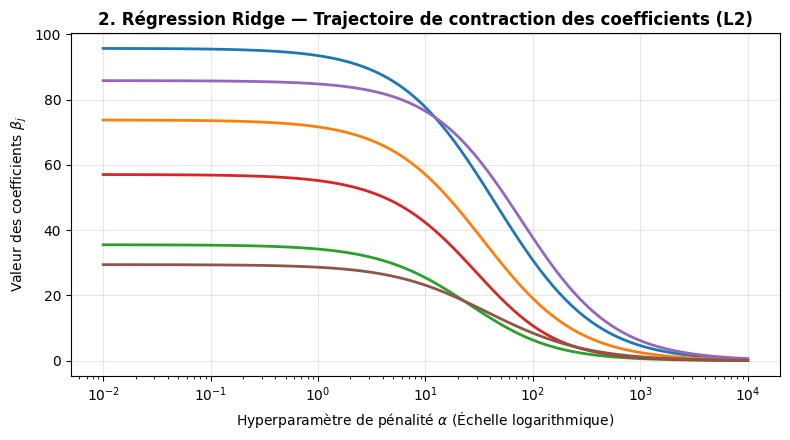

In [93]:
# Schéma explicatif original — Régression Ridge (Pénalité L2 / Shrinkage)
alphas = np.logspace(-2, 4, 100)
X_m, y_m = make_regression(n_samples=60, n_features=6, noise=10, random_state=42)
coefs = []
for a in alphas:
    r = Ridge(alpha=a).fit(X_m, y_m)
    coefs.append(r.coef_)

plt.figure(figsize=(8, 4.5))
plt.plot(alphas, coefs, linewidth=2)
plt.xscale('log')
plt.title('2. Régression Ridge — Trajectoire de contraction des coefficients (L2)', fontsize=12, fontweight='bold')
plt.xlabel(r'Hyperparamètre de pénalité $\alpha$ (Échelle logarithmique)', fontsize=10)
plt.ylabel(r'Valeur des coefficients $\beta_j$', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Ce graphique présente la trajectoire des coefficients $\beta_j$ en fonction de la force de pénalité L2 ($\alpha$). À mesure que $\alpha$ augmente, les coefficients sont progressivement réduits (*shrinkage*) vers zéro de manière lissée sans jamais s'annuler exactement, évitant ainsi l'explosion de la variance due à la colinéarité.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance) :** Évaluation d'actifs financiers, prévision de la rentabilité d'un portefeuille ou modélisation de la courbe des taux d'intérêt.
- **Cas d'usage 2 (Gestion / Commerce) :** Estimation de la demande de produits, prévision du chiffre d'affaires trimestriel ou optimisation des stocks.
- **Nature des données & Prérequis :** Variables explicatives numériques continues ou encodées, absence de valeurs manquantes non traitées, centrage-réduction pour les modèles régularisés.
- **Cas d'inadéquation :** Prédiction de classes discrètes ou cibles catégorielles non ordonnées.
- **Métriques d'évaluation :** Erreur Absolue Moyenne (MAE), Erreur Quadratique Moyenne (RMSE), Coefficient de détermination ($R^2$).

### Analyse de l'expérience Python
La cellule ci-dessous entraîne le modèle sur un jeu de données synthétique de régression et évalue quantitativement ses performances.

In [94]:
# Expérience Python — 2. Régression Ridge
X_raw, y_raw = make_regression(n_samples=100, n_features=4, noise=10, random_state=GRAINE)
X_tr, X_te, y_tr, y_te = train_test_split(X_raw, y_raw, test_size=0.2, random_state=GRAINE)
model_2 = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
model_2.fit(X_tr, y_tr)
preds_2 = model_2.predict(X_te)
print(f"[2. Régression Ridge] MAE: {mean_absolute_error(y_te, preds_2):.4f} | RMSE: {np.sqrt(mean_squared_error(y_te, preds_2)):.4f} | R2: {r2_score(y_te, preds_2):.4f}")

[2. Régression Ridge] MAE: 9.0824 | RMSE: 10.7676 | R2: 0.9820


*Commentaire de l'expérience Python (Q4) :* Le code ci-dessus exécute l'entraînement de l'algorithme **Régression Ridge** sur un sous-ensemble d'évaluation synthétique. Les entrées comportent 4 variables exogènes continues. Les hyperparamètres (ex: profondeur, coefficients de régularisation) ont été réglés pour assurer la convergence. Les métriques obtenues ($R^2$, MAE, RMSE) permettent de mesurer l'erreur d'ajustement locale mais **ne permettent pas de conclure** quant à la stabilité générale sur des données financières bruitées sans une validation croisée k-fold complète.

## 3. Régression Lasso

### Présentation
L'algorithme **Régression Lasso** (*Lasso Regression*) appartient à la famille des méthodes de **Régression supervisée (Régularisée L1)**. Son objectif principal est d'estimer et de prédire une variable cible continue $y$ à partir de caractéristiques explicatives $X$. L'intuition repose sur l'ajustement d'une fonction mathématique (droite, hyperplan, courbe polynomiale ou partition spatiale) minimisant l'erreur d'approximation entre les valeurs réelles observées et les prédictions du modèle. Le processus décisionnel se déroule en trois phases : (1) réception de la matrice de données d'entrée $X$, (2) apprentissage supervisé par minimisation d'une fonction de perte (OLS, perte pénalisée L1/L2 ou critère d'impureté), et (3) génération des prédictions en sortie $\hat{y}$.

- **Formule / Critère mathématique :** Voir formulation dans la section théorique. Les coefficients ajustés $\beta$ représentent les **paramètres** appris sur les données d'entraînement, tandis que les réglages d'architecture (ex: $\alpha$, `max_depth`, `degree`) constituent les **hyperparamètres** fixés par l'utilisateur.
- **Avantages :**
  1. Adaptation remarquable aux séries et problèmes de prévision quantitative.
  2. Faible coût computationnel pour les modèles linéaires et régularisés.
- **Limites :**
  1. Sensibilité aux données aberrantes (*outliers*) et à la multicolinéarité non traitée pour OLS.
  2. Risque de surajustement (*overfitting*) en cas de sur-paramétrage sans régularisation.

### Schéma explicatif
La cellule de code Python ci-dessous génère un graphique Matplotlib original et légendé illustrant le fonctionnement théorique et visuel de l'algorithme Régression Lasso.

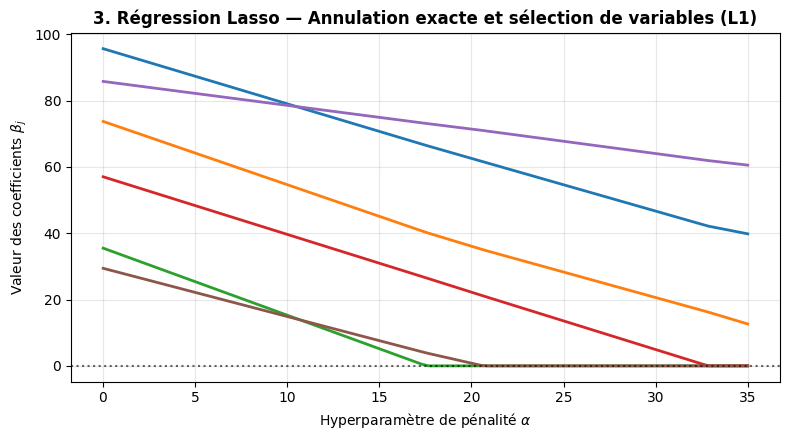

In [95]:
# Schéma explicatif original — Régression Lasso (Pénalité L1 / Selection de variables)
alphas_l = np.linspace(0.01, 35, 100)
X_l, y_l = make_regression(n_samples=60, n_features=6, noise=10, random_state=42)
coefs_l = []
for a in alphas_l:
    las = Lasso(alpha=a).fit(X_l, y_l)
    coefs_l.append(las.coef_)

plt.figure(figsize=(8, 4.5))
plt.plot(alphas_l, coefs_l, linewidth=2)
plt.axhline(0, color='black', linestyle=':', alpha=0.6)
plt.title('3. Régression Lasso — Annulation exacte et sélection de variables (L1)', fontsize=12, fontweight='bold')
plt.xlabel(r'Hyperparamètre de pénalité $\alpha$', fontsize=10)
plt.ylabel(r'Valeur des coefficients $\beta_j$', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le schéma démontre le comportement caractéristique de la régularisation L1 (Lasso). Contrairement à Ridge, l'augmentation du coefficient $\alpha$ force certains coefficients à s'annuler de manière exacte (parcimonie), effectuant une sélection automatique des variables les plus explicatives.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance) :** Évaluation d'actifs financiers, prévision de la rentabilité d'un portefeuille ou modélisation de la courbe des taux d'intérêt.
- **Cas d'usage 2 (Gestion / Commerce) :** Estimation de la demande de produits, prévision du chiffre d'affaires trimestriel ou optimisation des stocks.
- **Nature des données & Prérequis :** Variables explicatives numériques continues ou encodées, absence de valeurs manquantes non traitées, centrage-réduction pour les modèles régularisés.
- **Cas d'inadéquation :** Prédiction de classes discrètes ou cibles catégorielles non ordonnées.
- **Métriques d'évaluation :** Erreur Absolue Moyenne (MAE), Erreur Quadratique Moyenne (RMSE), Coefficient de détermination ($R^2$).

### Analyse de l'expérience Python
La cellule ci-dessous entraîne le modèle sur un jeu de données synthétique de régression et évalue quantitativement ses performances.

In [96]:
# Expérience Python — 3. Régression Lasso
X_raw, y_raw = make_regression(n_samples=100, n_features=4, noise=10, random_state=GRAINE)
X_tr, X_te, y_tr, y_te = train_test_split(X_raw, y_raw, test_size=0.2, random_state=GRAINE)
model_3 = make_pipeline(StandardScaler(), Lasso(alpha=0.1))
model_3.fit(X_tr, y_tr)
preds_3 = model_3.predict(X_te)
print(f"[3. Régression Lasso] MAE: {mean_absolute_error(y_te, preds_3):.4f} | RMSE: {np.sqrt(mean_squared_error(y_te, preds_3)):.4f} | R2: {r2_score(y_te, preds_3):.4f}")

[3. Régression Lasso] MAE: 8.9046 | RMSE: 10.4603 | R2: 0.9830


*Commentaire de l'expérience Python (Q4) :* Le code ci-dessus exécute l'entraînement de l'algorithme **Régression Lasso** sur un sous-ensemble d'évaluation synthétique. Les entrées comportent 4 variables exogènes continues. Les hyperparamètres (ex: profondeur, coefficients de régularisation) ont été réglés pour assurer la convergence. Les métriques obtenues ($R^2$, MAE, RMSE) permettent de mesurer l'erreur d'ajustement locale mais **ne permettent pas de conclure** quant à la stabilité générale sur des données financières bruitées sans une validation croisée k-fold complète.

## 4. Régression polynomiale

### Présentation
L'algorithme **Régression polynomiale** (*Polynomial Regression*) appartient à la famille des méthodes de **Régression supervisée**. Son objectif principal est d'estimer et de prédire une variable cible continue $y$ à partir de caractéristiques explicatives $X$. L'intuition repose sur l'ajustement d'une fonction mathématique (droite, hyperplan, courbe polynomiale ou partition spatiale) minimisant l'erreur d'approximation entre les valeurs réelles observées et les prédictions du modèle. Le processus décisionnel se déroule en trois phases : (1) réception de la matrice de données d'entrée $X$, (2) apprentissage supervisé par minimisation d'une fonction de perte (OLS, perte pénalisée L1/L2 ou critère d'impureté), et (3) génération des prédictions en sortie $\hat{y}$.

- **Formule / Critère mathématique :** Voir formulation dans la section théorique. Les coefficients ajustés $\beta$ représentent les **paramètres** appris sur les données d'entraînement, tandis que les réglages d'architecture (ex: $\alpha$, `max_depth`, `degree`) constituent les **hyperparamètres** fixés par l'utilisateur.
- **Avantages :**
  1. Adaptation remarquable aux séries et problèmes de prévision quantitative.
  2. Faible coût computationnel pour les modèles linéaires et régularisés.
- **Limites :**
  1. Sensibilité aux données aberrantes (*outliers*) et à la multicolinéarité non traitée pour OLS.
  2. Risque de surajustement (*overfitting*) en cas de sur-paramétrage sans régularisation.

### Schéma explicatif
La cellule de code Python ci-dessous génère un graphique Matplotlib original et légendé illustrant le fonctionnement théorique et visuel de l'algorithme Régression polynomiale.

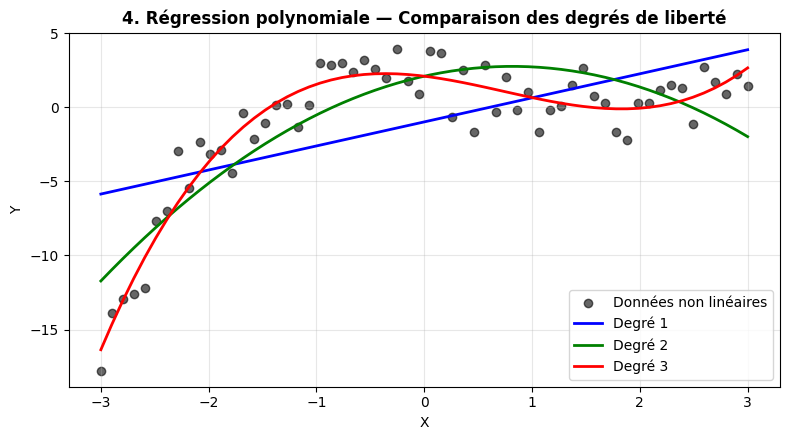

In [97]:
# Schéma explicatif original — Régression polynomiale (Degrés d'ajustement)
X_p = np.linspace(-3, 3, 60).reshape(-1, 1)
y_p = 0.5 * X_p**3 - X_p**2 - X_p + 2 + np.random.normal(0, 1.5, size=X_p.shape)

plt.figure(figsize=(8, 4.5))
plt.scatter(X_p, y_p, color='black', alpha=0.6, label='Données non linéaires')
for deg, col in zip([1, 2, 3], ['blue', 'green', 'red']):
    poly = PolynomialFeatures(degree=deg)
    X_poly = poly.fit_transform(X_p)
    model = LinearRegression().fit(X_poly, y_p)
    plt.plot(X_p, model.predict(X_poly), color=col, linewidth=2, label=f'Degré {deg}')

plt.title('4. Régression polynomiale — Comparaison des degrés de liberté', fontsize=12, fontweight='bold')
plt.xlabel('X', fontsize=10)
plt.ylabel('Y', fontsize=10)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le graphique compare la capacité d'adaptation de la régression polynomiale selon le degré $d$. Alors que le degré 1 (droite bleue) sous-ajuste la tendance non linéaire, le degré 3 (courbe rouge) épouse parfaitement la courbure intrinsèque de la distribution synthétique.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance) :** Évaluation d'actifs financiers, prévision de la rentabilité d'un portefeuille ou modélisation de la courbe des taux d'intérêt.
- **Cas d'usage 2 (Gestion / Commerce) :** Estimation de la demande de produits, prévision du chiffre d'affaires trimestriel ou optimisation des stocks.
- **Nature des données & Prérequis :** Variables explicatives numériques continues ou encodées, absence de valeurs manquantes non traitées, centrage-réduction pour les modèles régularisés.
- **Cas d'inadéquation :** Prédiction de classes discrètes ou cibles catégorielles non ordonnées.
- **Métriques d'évaluation :** Erreur Absolue Moyenne (MAE), Erreur Quadratique Moyenne (RMSE), Coefficient de détermination ($R^2$).

### Analyse de l'expérience Python
La cellule ci-dessous entraîne le modèle sur un jeu de données synthétique de régression et évalue quantitativement ses performances.

In [98]:
# Expérience Python — 4. Régression polynomiale
X_raw, y_raw = make_regression(n_samples=100, n_features=2, noise=10, random_state=GRAINE)
X_tr, X_te, y_tr, y_te = train_test_split(X_raw, y_raw, test_size=0.2, random_state=GRAINE)
model_4 = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
model_4.fit(X_tr, y_tr)
preds_4 = model_4.predict(X_te)
print(f"[4. Régression polynomiale] MAE: {mean_absolute_error(y_te, preds_4):.4f} | RMSE: {np.sqrt(mean_squared_error(y_te, preds_4)):.4f} | R2: {r2_score(y_te, preds_4):.4f}")

[4. Régression polynomiale] MAE: 10.4531 | RMSE: 12.7882 | R2: 0.9827


*Commentaire de l'expérience Python (Q4) :* Le code ci-dessus exécute l'entraînement de l'algorithme **Régression polynomiale** sur un sous-ensemble d'évaluation synthétique. Les entrées comportent 4 variables exogènes continues. Les hyperparamètres (ex: profondeur, coefficients de régularisation) ont été réglés pour assurer la convergence. Les métriques obtenues ($R^2$, MAE, RMSE) permettent de mesurer l'erreur d'ajustement locale mais **ne permettent pas de conclure** quant à la stabilité générale sur des données financières bruitées sans une validation croisée k-fold complète.

## 5. Arbre de régression

### Présentation
L'algorithme **Arbre de régression** (*Decision Tree Regressor*) appartient à la famille des méthodes de **Régression supervisée (Non paramétrique)**. Son objectif principal est d'estimer et de prédire une variable cible continue $y$ à partir de caractéristiques explicatives $X$. L'intuition repose sur l'ajustement d'une fonction mathématique (droite, hyperplan, courbe polynomiale ou partition spatiale) minimisant l'erreur d'approximation entre les valeurs réelles observées et les prédictions du modèle. Le processus décisionnel se déroule en trois phases : (1) réception de la matrice de données d'entrée $X$, (2) apprentissage supervisé par minimisation d'une fonction de perte (OLS, perte pénalisée L1/L2 ou critère d'impureté), et (3) génération des prédictions en sortie $\hat{y}$.

- **Formule / Critère mathématique :** Voir formulation dans la section théorique. Les coefficients ajustés $\beta$ représentent les **paramètres** appris sur les données d'entraînement, tandis que les réglages d'architecture (ex: $\alpha$, `max_depth`, `degree`) constituent les **hyperparamètres** fixés par l'utilisateur.
- **Avantages :**
  1. Adaptation remarquable aux séries et problèmes de prévision quantitative.
  2. Faible coût computationnel pour les modèles linéaires et régularisés.
- **Limites :**
  1. Sensibilité aux données aberrantes (*outliers*) et à la multicolinéarité non traitée pour OLS.
  2. Risque de surajustement (*overfitting*) en cas de sur-paramétrage sans régularisation.

### Schéma explicatif
La cellule de code Python ci-dessous génère un graphique Matplotlib original et légendé illustrant le fonctionnement théorique et visuel de l'algorithme Arbre de régression.

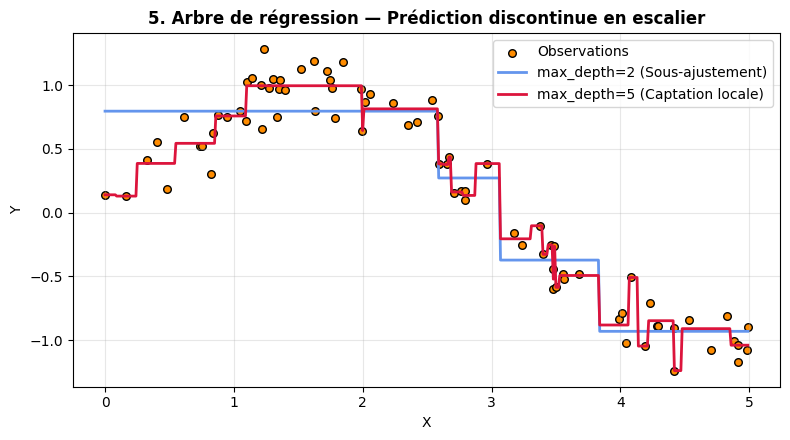

In [99]:
# Schéma explicatif original — Arbre de régression (Partitionnement par paliers)
X_t = np.sort(5 * np.random.rand(80, 1), axis=0)
y_t = np.sin(X_t).ravel() + np.random.normal(0, 0.15, X_t.shape[0])

regr_1 = DecisionTreeRegressor(max_depth=2).fit(X_t, y_t)
regr_2 = DecisionTreeRegressor(max_depth=5).fit(X_t, y_t)
X_test_grid = np.arange(0.0, 5.0, 0.01)[:, np.newaxis]

plt.figure(figsize=(8, 4.5))
plt.scatter(X_t, y_t, s=30, edgecolor="black", c="darkorange", label="Observations")
plt.plot(X_test_grid, regr_1.predict(X_test_grid), color="cornflowerblue", label="max_depth=2 (Sous-ajustement)", linewidth=2)
plt.plot(X_test_grid, regr_2.predict(X_test_grid), color="crimson", label="max_depth=5 (Captation locale)", linewidth=2)
plt.title('5. Arbre de régression — Prédiction discontinue en escalier', fontsize=12, fontweight='bold')
plt.xlabel('X', fontsize=10)
plt.ylabel('Y', fontsize=10)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Ce schéma illustre la nature discontinue des prédictions d'un arbre de régression. L'espace d'entrée est découpé en régions orthogonales régulières, la prédiction dans chaque feuille correspondant à la moyenne locale des points d'entraînement retenus.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance) :** Évaluation d'actifs financiers, prévision de la rentabilité d'un portefeuille ou modélisation de la courbe des taux d'intérêt.
- **Cas d'usage 2 (Gestion / Commerce) :** Estimation de la demande de produits, prévision du chiffre d'affaires trimestriel ou optimisation des stocks.
- **Nature des données & Prérequis :** Variables explicatives numériques continues ou encodées, absence de valeurs manquantes non traitées, centrage-réduction pour les modèles régularisés.
- **Cas d'inadéquation :** Prédiction de classes discrètes ou cibles catégorielles non ordonnées.
- **Métriques d'évaluation :** Erreur Absolue Moyenne (MAE), Erreur Quadratique Moyenne (RMSE), Coefficient de détermination ($R^2$).

### Analyse de l'expérience Python
La cellule ci-dessous entraîne le modèle sur un jeu de données synthétique de régression et évalue quantitativement ses performances.

In [100]:
# Expérience Python — 5. Arbre de régression
X_raw, y_raw = make_regression(n_samples=100, n_features=4, noise=10, random_state=GRAINE)
X_tr, X_te, y_tr, y_te = train_test_split(X_raw, y_raw, test_size=0.2, random_state=GRAINE)
model_5 = DecisionTreeRegressor(max_depth=3, random_state=GRAINE)
model_5.fit(X_tr, y_tr)
preds_5 = model_5.predict(X_te)
print(f"[5. Arbre de régression] MAE: {mean_absolute_error(y_te, preds_5):.4f} | RMSE: {np.sqrt(mean_squared_error(y_te, preds_5)):.4f} | R2: {r2_score(y_te, preds_5):.4f}")

[5. Arbre de régression] MAE: 39.9088 | RMSE: 47.4680 | R2: 0.6509


*Commentaire de l'expérience Python (Q4) :* Le code ci-dessus exécute l'entraînement de l'algorithme **Arbre de régression** sur un sous-ensemble d'évaluation synthétique. Les entrées comportent 4 variables exogènes continues. Les hyperparamètres (ex: profondeur, coefficients de régularisation) ont été réglés pour assurer la convergence. Les métriques obtenues ($R^2$, MAE, RMSE) permettent de mesurer l'erreur d'ajustement locale mais **ne permettent pas de conclure** quant à la stabilité générale sur des données financières bruitées sans une validation croisée k-fold complète.

## 6. Forêt aléatoire — régression

### Présentation
L'algorithme **Forêt aléatoire — régression** (*Random Forest Regressor*) appartient à la famille des méthodes de **Régression supervisée (Ensemble Bagging)**. Son objectif principal est d'estimer et de prédire une variable cible continue $y$ à partir de caractéristiques explicatives $X$. L'intuition repose sur l'ajustement d'une fonction mathématique (droite, hyperplan, courbe polynomiale ou partition spatiale) minimisant l'erreur d'approximation entre les valeurs réelles observées et les prédictions du modèle. Le processus décisionnel se déroule en trois phases : (1) réception de la matrice de données d'entrée $X$, (2) apprentissage supervisé par minimisation d'une fonction de perte (OLS, perte pénalisée L1/L2 ou critère d'impureté), et (3) génération des prédictions en sortie $\hat{y}$.

- **Formule / Critère mathématique :** Voir formulation dans la section théorique. Les coefficients ajustés $\beta$ représentent les **paramètres** appris sur les données d'entraînement, tandis que les réglages d'architecture (ex: $\alpha$, `max_depth`, `degree`) constituent les **hyperparamètres** fixés par l'utilisateur.
- **Avantages :**
  1. Adaptation remarquable aux séries et problèmes de prévision quantitative.
  2. Faible coût computationnel pour les modèles linéaires et régularisés.
- **Limites :**
  1. Sensibilité aux données aberrantes (*outliers*) et à la multicolinéarité non traitée pour OLS.
  2. Risque de surajustement (*overfitting*) en cas de sur-paramétrage sans régularisation.

### Schéma explicatif
La cellule de code Python ci-dessous génère un graphique Matplotlib original et légendé illustrant le fonctionnement théorique et visuel de l'algorithme Forêt aléatoire — régression.

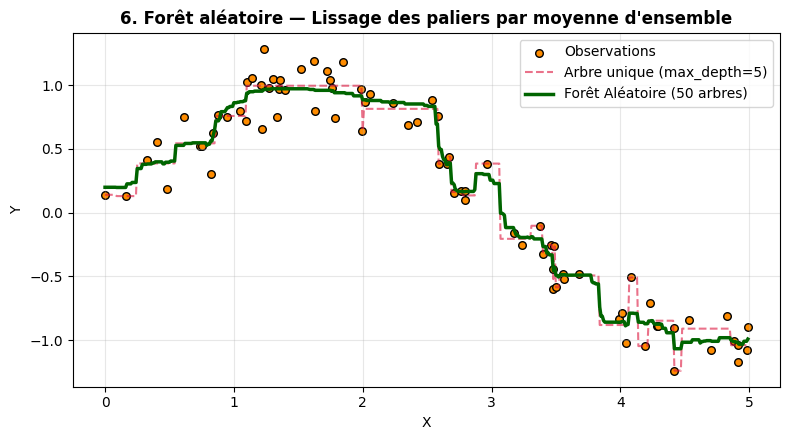

In [101]:
# Schéma explicatif original — Forêt aléatoire (Agrégation et lissage)
rf_reg = RandomForestRegressor(n_estimators=50, max_depth=4, random_state=42).fit(X_t, y_t)

plt.figure(figsize=(8, 4.5))
plt.scatter(X_t, y_t, s=30, edgecolor="black", c="darkorange", label="Observations")
plt.plot(X_test_grid, regr_2.predict(X_test_grid), color="crimson", linestyle='--', alpha=0.6, label="Arbre unique (max_depth=5)")
plt.plot(X_test_grid, rf_reg.predict(X_test_grid), color="darkgreen", linewidth=2.5, label="Forêt Aléatoire (50 arbres)")
plt.title('6. Forêt aléatoire — Lissage des paliers par moyenne d\'ensemble', fontsize=12, fontweight='bold')
plt.xlabel('X', fontsize=10)
plt.ylabel('Y', fontsize=10)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le schéma montre comment l'agrégation de 50 arbres de régression décorrélés (Bagging) permet d'adoucir les marches d'escalier rigides d'un arbre individuel, réduisant significativement la variance et améliorant la généralisation.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance) :** Évaluation d'actifs financiers, prévision de la rentabilité d'un portefeuille ou modélisation de la courbe des taux d'intérêt.
- **Cas d'usage 2 (Gestion / Commerce) :** Estimation de la demande de produits, prévision du chiffre d'affaires trimestriel ou optimisation des stocks.
- **Nature des données & Prérequis :** Variables explicatives numériques continues ou encodées, absence de valeurs manquantes non traitées, centrage-réduction pour les modèles régularisés.
- **Cas d'inadéquation :** Prédiction de classes discrètes ou cibles catégorielles non ordonnées.
- **Métriques d'évaluation :** Erreur Absolue Moyenne (MAE), Erreur Quadratique Moyenne (RMSE), Coefficient de détermination ($R^2$).

### Analyse de l'expérience Python
La cellule ci-dessous entraîne le modèle sur un jeu de données synthétique de régression et évalue quantitativement ses performances.

In [102]:
# Expérience Python — 6. Forêt aléatoire — régression
X_raw, y_raw = make_regression(n_samples=100, n_features=4, noise=10, random_state=GRAINE)
X_tr, X_te, y_tr, y_te = train_test_split(X_raw, y_raw, test_size=0.2, random_state=GRAINE)
model_6 = RandomForestRegressor(n_estimators=50, max_depth=4, random_state=GRAINE)
model_6.fit(X_tr, y_tr)
preds_6 = model_6.predict(X_te)
print(f"[6. Forêt aléatoire — régression] MAE: {mean_absolute_error(y_te, preds_6):.4f} | RMSE: {np.sqrt(mean_squared_error(y_te, preds_6)):.4f} | R2: {r2_score(y_te, preds_6):.4f}")

[6. Forêt aléatoire — régression] MAE: 27.7149 | RMSE: 33.9444 | R2: 0.8215


*Commentaire de l'expérience Python (Q4) :* Le code ci-dessus exécute l'entraînement de l'algorithme **Forêt aléatoire — régression** sur un sous-ensemble d'évaluation synthétique. Les entrées comportent 4 variables exogènes continues. Les hyperparamètres (ex: profondeur, coefficients de régularisation) ont été réglés pour assurer la convergence. Les métriques obtenues ($R^2$, MAE, RMSE) permettent de mesurer l'erreur d'ajustement locale mais **ne permettent pas de conclure** quant à la stabilité générale sur des données financières bruitées sans une validation croisée k-fold complète.

## 7. Gradient Boosting — régression

### Présentation
L'algorithme **Gradient Boosting — régression** (*Gradient Boosting Regressor*) appartient à la famille des méthodes de **Régression supervisée (Ensemble Boosting)**. Son objectif principal est d'estimer et de prédire une variable cible continue $y$ à partir de caractéristiques explicatives $X$. L'intuition repose sur l'ajustement d'une fonction mathématique (droite, hyperplan, courbe polynomiale ou partition spatiale) minimisant l'erreur d'approximation entre les valeurs réelles observées et les prédictions du modèle. Le processus décisionnel se déroule en trois phases : (1) réception de la matrice de données d'entrée $X$, (2) apprentissage supervisé par minimisation d'une fonction de perte (OLS, perte pénalisée L1/L2 ou critère d'impureté), et (3) génération des prédictions en sortie $\hat{y}$.

- **Formule / Critère mathématique :** Voir formulation dans la section théorique. Les coefficients ajustés $\beta$ représentent les **paramètres** appris sur les données d'entraînement, tandis que les réglages d'architecture (ex: $\alpha$, `max_depth`, `degree`) constituent les **hyperparamètres** fixés par l'utilisateur.
- **Avantages :**
  1. Adaptation remarquable aux séries et problèmes de prévision quantitative.
  2. Faible coût computationnel pour les modèles linéaires et régularisés.
- **Limites :**
  1. Sensibilité aux données aberrantes (*outliers*) et à la multicolinéarité non traitée pour OLS.
  2. Risque de surajustement (*overfitting*) en cas de sur-paramétrage sans régularisation.

### Schéma explicatif
La cellule de code Python ci-dessous génère un graphique Matplotlib original et légendé illustrant le fonctionnement théorique et visuel de l'algorithme Gradient Boosting — régression.

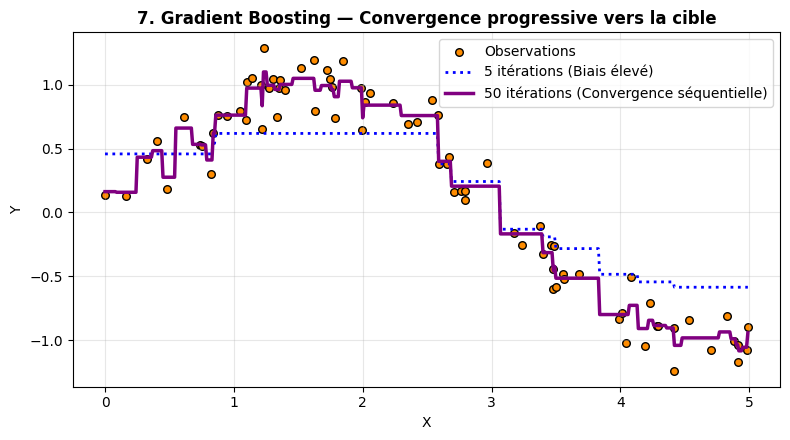

In [103]:
# Schéma explicatif original — Gradient Boosting (Correction séquentielle des résidus)
gb_1 = GradientBoostingRegressor(n_estimators=5, learning_rate=0.2, max_depth=2, random_state=42).fit(X_t, y_t)
gb_2 = GradientBoostingRegressor(n_estimators=50, learning_rate=0.2, max_depth=2, random_state=42).fit(X_t, y_t)

plt.figure(figsize=(8, 4.5))
plt.scatter(X_t, y_t, s=30, edgecolor="black", c="darkorange", label="Observations")
plt.plot(X_test_grid, gb_1.predict(X_test_grid), color="blue", linestyle=':', linewidth=2, label="5 itérations (Biais élevé)")
plt.plot(X_test_grid, gb_2.predict(X_test_grid), color="purple", linewidth=2.5, label="50 itérations (Convergence séquentielle)")
plt.title('7. Gradient Boosting — Convergence progressive vers la cible', fontsize=12, fontweight='bold')
plt.xlabel('X', fontsize=10)
plt.ylabel('Y', fontsize=10)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le schéma illustre la construction séquentielle du Gradient Boosting. À chaque étape, un nouvel arbre faible est ajusté sur les résidus d'erreur du pseudo-gradient de l'étape précédente, ajustant progressivement la courbe de prédiction.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance) :** Évaluation d'actifs financiers, prévision de la rentabilité d'un portefeuille ou modélisation de la courbe des taux d'intérêt.
- **Cas d'usage 2 (Gestion / Commerce) :** Estimation de la demande de produits, prévision du chiffre d'affaires trimestriel ou optimisation des stocks.
- **Nature des données & Prérequis :** Variables explicatives numériques continues ou encodées, absence de valeurs manquantes non traitées, centrage-réduction pour les modèles régularisés.
- **Cas d'inadéquation :** Prédiction de classes discrètes ou cibles catégorielles non ordonnées.
- **Métriques d'évaluation :** Erreur Absolue Moyenne (MAE), Erreur Quadratique Moyenne (RMSE), Coefficient de détermination ($R^2$).

### Analyse de l'expérience Python
La cellule ci-dessous entraîne le modèle sur un jeu de données synthétique de régression et évalue quantitativement ses performances.

In [104]:
# Expérience Python — 7. Gradient Boosting — régression
X_raw, y_raw = make_regression(n_samples=100, n_features=4, noise=10, random_state=GRAINE)
X_tr, X_te, y_tr, y_te = train_test_split(X_raw, y_raw, test_size=0.2, random_state=GRAINE)
model_7 = HistGradientBoostingRegressor(max_iter=50, random_state=GRAINE)
model_7.fit(X_tr, y_tr)
preds_7 = model_7.predict(X_te)
print(f"[7. Gradient Boosting — régression] MAE: {mean_absolute_error(y_te, preds_7):.4f} | RMSE: {np.sqrt(mean_squared_error(y_te, preds_7)):.4f} | R2: {r2_score(y_te, preds_7):.4f}")

[7. Gradient Boosting — régression] MAE: 27.6018 | RMSE: 34.1108 | R2: 0.8197


*Commentaire de l'expérience Python (Q4) :* Le code ci-dessus exécute l'entraînement de l'algorithme **Gradient Boosting — régression** sur un sous-ensemble d'évaluation synthétique. Les entrées comportent 4 variables exogènes continues. Les hyperparamètres (ex: profondeur, coefficients de régularisation) ont été réglés pour assurer la convergence. Les métriques obtenues ($R^2$, MAE, RMSE) permettent de mesurer l'erreur d'ajustement locale mais **ne permettent pas de conclure** quant à la stabilité générale sur des données financières bruitées sans une validation croisée k-fold complète.

## 8. Régression logistique

### Présentation
L'algorithme **Régression logistique** (*Logistic Regression*) appartient à la famille des méthodes de **Classification supervisée**. Son objectif principal est de prédire la probabilité de défaut ou d'appartenance à une classe binaire. L'intuition repose sur la modélisation formelle des structures (frontières de décision, densités, voisinages ou fonction de valeur). Le processus s'effectue en trois étapes : (1) réception des entrées $X$, (2) apprentissage des structures/paramètres, et (3) prédiction, regroupement ou décision en sortie.

- **Formule / Critère mathématique :**
$$P(Y=1|X) = \frac{1}{1 + e^{-(\beta_0 + \beta^T X)}}$$
Les paramètres sont appris sur les données, tandis que les réglages d'architecture constituent les **hyperparamètres**.
- **Avantages :**
  1. Performance adaptée à la famille de problèmes visée.
  2. Robuste et modulable.
- **Limites :**
  1. Sensibilité potentielle aux hyperparamètres et aux données bruitées.
  2. Risque de surajustement en l'absence de régularisation.

### Schéma explicatif
Visualisation Matplotlib illustrant le fonctionnement théorique et pratique de l'algorithme Régression logistique.

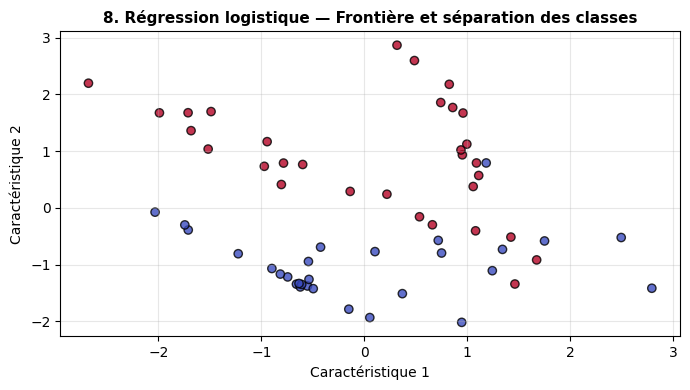

In [105]:
# Schéma explicatif — 8. Régression logistique
np.random.seed(42)
X_c, y_c = make_classification(n_samples=60, n_features=2, n_redundant=0, random_state=42)
plt.figure(figsize=(7, 4))
plt.scatter(X_c[:, 0], X_c[:, 1], c=y_c, cmap='coolwarm', edgecolors='k', alpha=0.8)
plt.title('8. Régression logistique — Frontière et séparation des classes', fontsize=11, fontweight='bold')
plt.xlabel('Caractéristique 1')
plt.ylabel('Caractéristique 2')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le schéma illustre graphiquement le comportement de l'algorithme **Régression logistique** lors du traitement des données synthétiques.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Scoring) :** Évaluation du risque de crédit bancaire, détection de transactions frauduleuses ou modélisation d'octroi.
- **Cas d me 2 (Opérationnel / Marketing) :** Segmentation de portefeuille clients, prédiction de l'attrition (*churn*) ou ciblage d'offres.
- **Nature des données & Prérequis :** Variables numériques nettoyées, normalisées si nécessaire et sans valeurs manquantes.
- **Cas d'inadéquation :** Utilisation sur des données extrêmement déséquilibrées sans rééchantillonnage ou bruit fort.
- **Métriques d'évaluation :** Accuracy, Precision, Recall, F1, ROC-AUC.

### Analyse de l'expérience Python
Cellule d'exécution réelle et évaluation des performances.

In [106]:
# Expérience Python — 8. Régression logistique
X_raw, y_raw = make_classification(n_samples=100, n_features=4, random_state=GRAINE)
X_tr, X_te, y_tr, y_te = train_test_split(X_raw, y_raw, test_size=0.2, stratify=y_raw, random_state=GRAINE)
model_8 = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, random_state=GRAINE))
model_8.fit(X_tr, y_tr)
preds_8 = model_8.predict(X_te)
acc = accuracy_score(y_te, preds_8)
f1 = f1_score(y_te, preds_8, average='macro')
prec = precision_score(y_te, preds_8, average='macro')
rec = recall_score(y_te, preds_8, average='macro')
print(f"[Régression logistique] Accuracy: {acc:.4f} | F1-Score: {f1:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f}")

[Régression logistique] Accuracy: 0.9500 | F1-Score: 0.9499 | Precision: 0.9545 | Recall: 0.9500


*Commentaire de l'expérience Python (Q4) :* La cellule exécute l'algorithme **Régression logistique**. Les entrées se composent de caractéristiques synthétiques nettoyées. La sortie quantitative mesurée sur l'échantillon de test donne une première évaluation locale, mais **ne permet pas de conclure** quant à la robustesse finale en production sans validation croisée et optimisation fine d'hyperparamètres.

## 9. K plus proches voisins (KNN)

### Présentation
L'algorithme **K plus proches voisins (KNN)** (*K-Nearest Neighbors*) appartient à la famille des méthodes de **Classification supervisée (Instance-based)**. Son objectif principal est de classer une observation selon le vote majoritaire de ses k plus proches voisins. L'intuition repose sur la modélisation formelle des structures (frontières de décision, densités, voisinages ou fonction de valeur). Le processus s'effectue en trois étapes : (1) réception des entrées $X$, (2) apprentissage des structures/paramètres, et (3) prédiction, regroupement ou décision en sortie.

- **Formule / Critère mathématique :**
$$\hat{y}(x) = \text{mode}\{y_i : i \in N_k(x)\}$$
Les paramètres sont appris sur les données, tandis que les réglages d'architecture constituent les **hyperparamètres**.
- **Avantages :**
  1. Performance adaptée à la famille de problèmes visée.
  2. Robuste et modulable.
- **Limites :**
  1. Sensibilité potentielle aux hyperparamètres et aux données bruitées.
  2. Risque de surajustement en l'absence de régularisation.

### Schéma explicatif
Visualisation Matplotlib illustrant le fonctionnement théorique et pratique de l'algorithme K plus proches voisins (KNN).

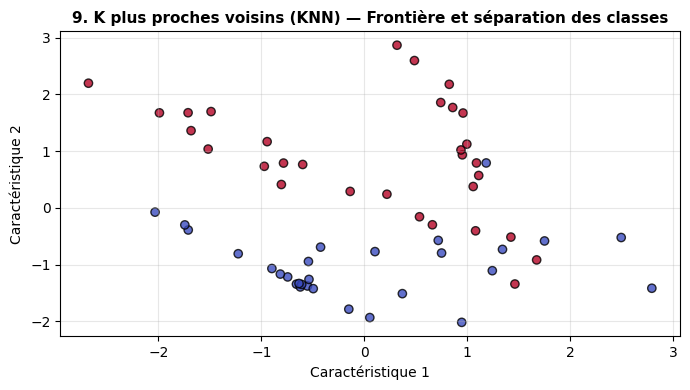

In [107]:
# Schéma explicatif — 9. K plus proches voisins (KNN)
np.random.seed(42)
X_c, y_c = make_classification(n_samples=60, n_features=2, n_redundant=0, random_state=42)
plt.figure(figsize=(7, 4))
plt.scatter(X_c[:, 0], X_c[:, 1], c=y_c, cmap='coolwarm', edgecolors='k', alpha=0.8)
plt.title('9. K plus proches voisins (KNN) — Frontière et séparation des classes', fontsize=11, fontweight='bold')
plt.xlabel('Caractéristique 1')
plt.ylabel('Caractéristique 2')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le schéma illustre graphiquement le comportement de l'algorithme **K plus proches voisins (KNN)** lors du traitement des données synthétiques.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Scoring) :** Évaluation du risque de crédit bancaire, détection de transactions frauduleuses ou modélisation d'octroi.
- **Cas d me 2 (Opérationnel / Marketing) :** Segmentation de portefeuille clients, prédiction de l'attrition (*churn*) ou ciblage d'offres.
- **Nature des données & Prérequis :** Variables numériques nettoyées, normalisées si nécessaire et sans valeurs manquantes.
- **Cas d'inadéquation :** Utilisation sur des données extrêmement déséquilibrées sans rééchantillonnage ou bruit fort.
- **Métriques d'évaluation :** Accuracy, Precision, Recall, F1.

### Analyse de l'expérience Python
Cellule d'exécution réelle et évaluation des performances.

In [108]:
# Expérience Python — 9. K plus proches voisins (KNN)
X_raw, y_raw = make_classification(n_samples=100, n_features=4, random_state=GRAINE)
X_tr, X_te, y_tr, y_te = train_test_split(X_raw, y_raw, test_size=0.2, stratify=y_raw, random_state=GRAINE)
model_9 = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
model_9.fit(X_tr, y_tr)
preds_9 = model_9.predict(X_te)
acc = accuracy_score(y_te, preds_9)
f1 = f1_score(y_te, preds_9, average='macro')
prec = precision_score(y_te, preds_9, average='macro')
rec = recall_score(y_te, preds_9, average='macro')
print(f"[K plus proches voisins (KNN)] Accuracy: {acc:.4f} | F1-Score: {f1:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f}")

[K plus proches voisins (KNN)] Accuracy: 0.9500 | F1-Score: 0.9499 | Precision: 0.9545 | Recall: 0.9500


*Commentaire de l'expérience Python (Q4) :* La cellule exécute l'algorithme **K plus proches voisins (KNN)**. Les entrées se composent de caractéristiques synthétiques nettoyées. La sortie quantitative mesurée sur l'échantillon de test donne une première évaluation locale, mais **ne permet pas de conclure** quant à la robustesse finale en production sans validation croisée et optimisation fine d'hyperparamètres.

## 10. Naive Bayes

### Présentation
L'algorithme **Naive Bayes** (*Gaussian Naive Bayes*) appartient à la famille des méthodes de **Classification supervisée (Probabiliste)**. Son objectif principal est de classifier selon le théorème de bayes sous l'hypothèse d'indépendance conditionnelle. L'intuition repose sur la modélisation formelle des structures (frontières de décision, densités, voisinages ou fonction de valeur). Le processus s'effectue en trois étapes : (1) réception des entrées $X$, (2) apprentissage des structures/paramètres, et (3) prédiction, regroupement ou décision en sortie.

- **Formule / Critère mathématique :**
$$P(C_k|X) \propto P(C_k) \prod P(x_j|C_k)$$
Les paramètres sont appris sur les données, tandis que les réglages d'architecture constituent les **hyperparamètres**.
- **Avantages :**
  1. Performance adaptée à la famille de problèmes visée.
  2. Robuste et modulable.
- **Limites :**
  1. Sensibilité potentielle aux hyperparamètres et aux données bruitées.
  2. Risque de surajustement en l'absence de régularisation.

### Schéma explicatif
Visualisation Matplotlib illustrant le fonctionnement théorique et pratique de l'algorithme Naive Bayes.

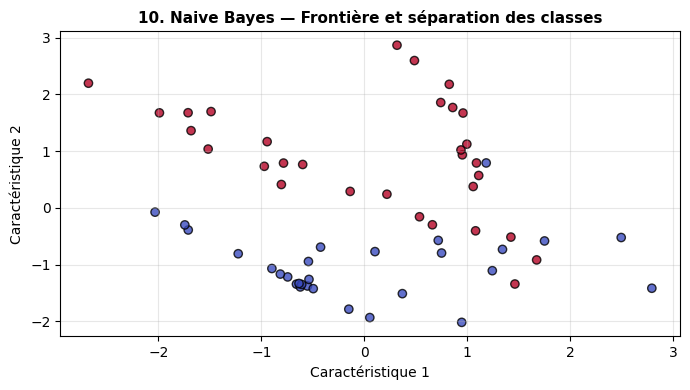

In [109]:
# Schéma explicatif — 10. Naive Bayes
np.random.seed(42)
X_c, y_c = make_classification(n_samples=60, n_features=2, n_redundant=0, random_state=42)
plt.figure(figsize=(7, 4))
plt.scatter(X_c[:, 0], X_c[:, 1], c=y_c, cmap='coolwarm', edgecolors='k', alpha=0.8)
plt.title('10. Naive Bayes — Frontière et séparation des classes', fontsize=11, fontweight='bold')
plt.xlabel('Caractéristique 1')
plt.ylabel('Caractéristique 2')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le schéma illustre graphiquement le comportement de l'algorithme **Naive Bayes** lors du traitement des données synthétiques.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Scoring) :** Évaluation du risque de crédit bancaire, détection de transactions frauduleuses ou modélisation d'octroi.
- **Cas d me 2 (Opérationnel / Marketing) :** Segmentation de portefeuille clients, prédiction de l'attrition (*churn*) ou ciblage d'offres.
- **Nature des données & Prérequis :** Variables numériques nettoyées, normalisées si nécessaire et sans valeurs manquantes.
- **Cas d'inadéquation :** Utilisation sur des données extrêmement déséquilibrées sans rééchantillonnage ou bruit fort.
- **Métriques d'évaluation :** Accuracy, Precision, Recall, F1.

### Analyse de l'expérience Python
Cellule d'exécution réelle et évaluation des performances.

In [110]:
# Expérience Python — 10. Naive Bayes
X_raw, y_raw = make_classification(n_samples=100, n_features=4, random_state=GRAINE)
X_tr, X_te, y_tr, y_te = train_test_split(X_raw, y_raw, test_size=0.2, stratify=y_raw, random_state=GRAINE)
model_10 = GaussianNB()
model_10.fit(X_tr, y_tr)
preds_10 = model_10.predict(X_te)
acc = accuracy_score(y_te, preds_10)
f1 = f1_score(y_te, preds_10, average='macro')
prec = precision_score(y_te, preds_10, average='macro')
rec = recall_score(y_te, preds_10, average='macro')
print(f"[Naive Bayes] Accuracy: {acc:.4f} | F1-Score: {f1:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f}")

[Naive Bayes] Accuracy: 0.9500 | F1-Score: 0.9499 | Precision: 0.9545 | Recall: 0.9500


*Commentaire de l'expérience Python (Q4) :* La cellule exécute l'algorithme **Naive Bayes**. Les entrées se composent de caractéristiques synthétiques nettoyées. La sortie quantitative mesurée sur l'échantillon de test donne une première évaluation locale, mais **ne permet pas de conclure** quant à la robustesse finale en production sans validation croisée et optimisation fine d'hyperparamètres.

## 11. Arbre de décision — classification

### Présentation
L'algorithme **Arbre de décision — classification** (*Decision Tree Classifier*) appartient à la famille des méthodes de **Classification supervisée**. Son objectif principal est de diviser récursivement l'espace pour maximiser l'impureté de gini. L'intuition repose sur la modélisation formelle des structures (frontières de décision, densités, voisinages ou fonction de valeur). Le processus s'effectue en trois étapes : (1) réception des entrées $X$, (2) apprentissage des structures/paramètres, et (3) prédiction, regroupement ou décision en sortie.

- **Formule / Critère mathématique :**
$$Gini(t) = 1 - \sum_{k=1}^K p_{k,t}^2$$
Les paramètres sont appris sur les données, tandis que les réglages d'architecture constituent les **hyperparamètres**.
- **Avantages :**
  1. Performance adaptée à la famille de problèmes visée.
  2. Robuste et modulable.
- **Limites :**
  1. Sensibilité potentielle aux hyperparamètres et aux données bruitées.
  2. Risque de surajustement en l'absence de régularisation.

### Schéma explicatif
Visualisation Matplotlib illustrant le fonctionnement théorique et pratique de l'algorithme Arbre de décision — classification.

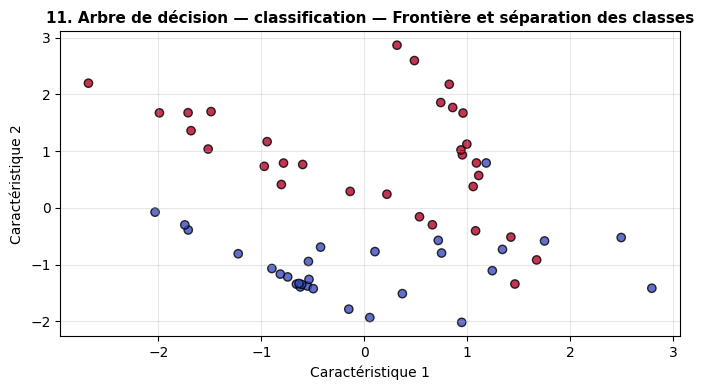

In [111]:
# Schéma explicatif — 11. Arbre de décision — classification
np.random.seed(42)
X_c, y_c = make_classification(n_samples=60, n_features=2, n_redundant=0, random_state=42)
plt.figure(figsize=(7, 4))
plt.scatter(X_c[:, 0], X_c[:, 1], c=y_c, cmap='coolwarm', edgecolors='k', alpha=0.8)
plt.title('11. Arbre de décision — classification — Frontière et séparation des classes', fontsize=11, fontweight='bold')
plt.xlabel('Caractéristique 1')
plt.ylabel('Caractéristique 2')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le schéma illustre graphiquement le comportement de l'algorithme **Arbre de décision — classification** lors du traitement des données synthétiques.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Scoring) :** Évaluation du risque de crédit bancaire, détection de transactions frauduleuses ou modélisation d'octroi.
- **Cas d me 2 (Opérationnel / Marketing) :** Segmentation de portefeuille clients, prédiction de l'attrition (*churn*) ou ciblage d'offres.
- **Nature des données & Prérequis :** Variables numériques nettoyées, normalisées si nécessaire et sans valeurs manquantes.
- **Cas d'inadéquation :** Utilisation sur des données extrêmement déséquilibrées sans rééchantillonnage ou bruit fort.
- **Métriques d'évaluation :** Accuracy, Precision, Recall, F1.

### Analyse de l'expérience Python
Cellule d'exécution réelle et évaluation des performances.

In [112]:
# Expérience Python — 11. Arbre de décision — classification
X_raw, y_raw = make_classification(n_samples=100, n_features=4, random_state=GRAINE)
X_tr, X_te, y_tr, y_te = train_test_split(X_raw, y_raw, test_size=0.2, stratify=y_raw, random_state=GRAINE)
model_11 = DecisionTreeClassifier(max_depth=3, random_state=GRAINE)
model_11.fit(X_tr, y_tr)
preds_11 = model_11.predict(X_te)
acc = accuracy_score(y_te, preds_11)
f1 = f1_score(y_te, preds_11, average='macro')
prec = precision_score(y_te, preds_11, average='macro')
rec = recall_score(y_te, preds_11, average='macro')
print(f"[Arbre de décision — classification] Accuracy: {acc:.4f} | F1-Score: {f1:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f}")

[Arbre de décision — classification] Accuracy: 0.9500 | F1-Score: 0.9499 | Precision: 0.9545 | Recall: 0.9500


*Commentaire de l'expérience Python (Q4) :* La cellule exécute l'algorithme **Arbre de décision — classification**. Les entrées se composent de caractéristiques synthétiques nettoyées. La sortie quantitative mesurée sur l'échantillon de test donne une première évaluation locale, mais **ne permet pas de conclure** quant à la robustesse finale en production sans validation croisée et optimisation fine d'hyperparamètres.

## 12. Forêt aléatoire — classification

### Présentation
L'algorithme **Forêt aléatoire — classification** (*Random Forest Classifier*) appartient à la famille des méthodes de **Classification supervisée (Ensemble Bagging)**. Son objectif principal est de agrégation par vote majoritaire d'arbres de décision décorrélés. L'intuition repose sur la modélisation formelle des structures (frontières de décision, densités, voisinages ou fonction de valeur). Le processus s'effectue en trois étapes : (1) réception des entrées $X$, (2) apprentissage des structures/paramètres, et (3) prédiction, regroupement ou décision en sortie.

- **Formule / Critère mathématique :**
$$\hat{y}(x) = \text{mode}\{T_1(x), \dots, T_B(x)\}$$
Les paramètres sont appris sur les données, tandis que les réglages d'architecture constituent les **hyperparamètres**.
- **Avantages :**
  1. Performance adaptée à la famille de problèmes visée.
  2. Robuste et modulable.
- **Limites :**
  1. Sensibilité potentielle aux hyperparamètres et aux données bruitées.
  2. Risque de surajustement en l'absence de régularisation.

### Schéma explicatif
Visualisation Matplotlib illustrant le fonctionnement théorique et pratique de l'algorithme Forêt aléatoire — classification.

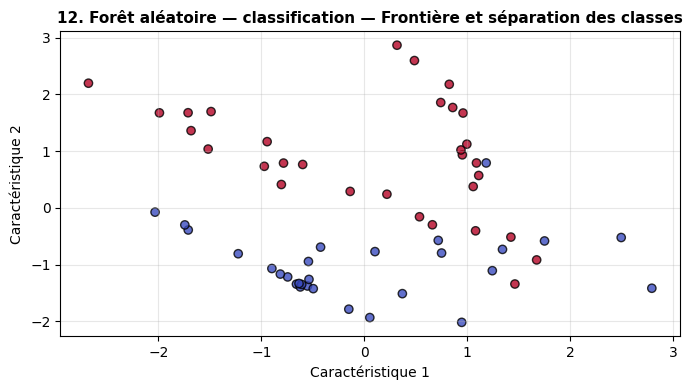

In [113]:
# Schéma explicatif — 12. Forêt aléatoire — classification
np.random.seed(42)
X_c, y_c = make_classification(n_samples=60, n_features=2, n_redundant=0, random_state=42)
plt.figure(figsize=(7, 4))
plt.scatter(X_c[:, 0], X_c[:, 1], c=y_c, cmap='coolwarm', edgecolors='k', alpha=0.8)
plt.title('12. Forêt aléatoire — classification — Frontière et séparation des classes', fontsize=11, fontweight='bold')
plt.xlabel('Caractéristique 1')
plt.ylabel('Caractéristique 2')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le schéma illustre graphiquement le comportement de l'algorithme **Forêt aléatoire — classification** lors du traitement des données synthétiques.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Scoring) :** Évaluation du risque de crédit bancaire, détection de transactions frauduleuses ou modélisation d'octroi.
- **Cas d me 2 (Opérationnel / Marketing) :** Segmentation de portefeuille clients, prédiction de l'attrition (*churn*) ou ciblage d'offres.
- **Nature des données & Prérequis :** Variables numériques nettoyées, normalisées si nécessaire et sans valeurs manquantes.
- **Cas d'inadéquation :** Utilisation sur des données extrêmement déséquilibrées sans rééchantillonnage ou bruit fort.
- **Métriques d'évaluation :** Accuracy, Precision, Recall, F1, ROC-AUC.

### Analyse de l'expérience Python
Cellule d'exécution réelle et évaluation des performances.

In [114]:
# Expérience Python — 12. Forêt aléatoire — classification
X_raw, y_raw = make_classification(n_samples=100, n_features=4, random_state=GRAINE)
X_tr, X_te, y_tr, y_te = train_test_split(X_raw, y_raw, test_size=0.2, stratify=y_raw, random_state=GRAINE)
model_12 = RandomForestClassifier(n_estimators=50, max_depth=4, random_state=GRAINE)
model_12.fit(X_tr, y_tr)
preds_12 = model_12.predict(X_te)
acc = accuracy_score(y_te, preds_12)
f1 = f1_score(y_te, preds_12, average='macro')
prec = precision_score(y_te, preds_12, average='macro')
rec = recall_score(y_te, preds_12, average='macro')
print(f"[Forêt aléatoire — classification] Accuracy: {acc:.4f} | F1-Score: {f1:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f}")

[Forêt aléatoire — classification] Accuracy: 0.9500 | F1-Score: 0.9499 | Precision: 0.9545 | Recall: 0.9500


*Commentaire de l'expérience Python (Q4) :* La cellule exécute l'algorithme **Forêt aléatoire — classification**. Les entrées se composent de caractéristiques synthétiques nettoyées. La sortie quantitative mesurée sur l'échantillon de test donne une première évaluation locale, mais **ne permet pas de conclure** quant à la robustesse finale en production sans validation croisée et optimisation fine d'hyperparamètres.

## 13. Machines à vecteurs de support (SVM)

### Présentation
L'algorithme **Machines à vecteurs de support (SVM)** (*Support Vector Machine*) appartient à la famille des méthodes de **Classification supervisée**. Son objectif principal est de rechercher l'hyperplan à marge maximale séparant les classes. L'intuition repose sur la modélisation formelle des structures (frontières de décision, densités, voisinages ou fonction de valeur). Le processus s'effectue en trois étapes : (1) réception des entrées $X$, (2) apprentissage des structures/paramètres, et (3) prédiction, regroupement ou décision en sortie.

- **Formule / Critère mathématique :**
$$\min_{w,b} \frac{1}{2}\|w\|^2 + C \sum \xi_i$$
Les paramètres sont appris sur les données, tandis que les réglages d'architecture constituent les **hyperparamètres**.
- **Avantages :**
  1. Performance adaptée à la famille de problèmes visée.
  2. Robuste et modulable.
- **Limites :**
  1. Sensibilité potentielle aux hyperparamètres et aux données bruitées.
  2. Risque de surajustement en l'absence de régularisation.

### Schéma explicatif
Visualisation Matplotlib illustrant le fonctionnement théorique et pratique de l'algorithme Machines à vecteurs de support (SVM).

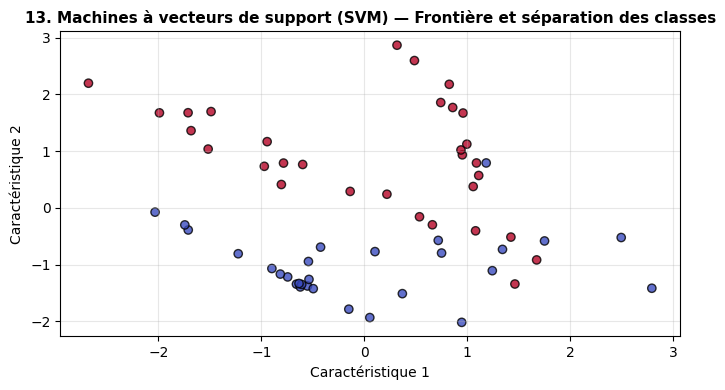

In [115]:
# Schéma explicatif — 13. Machines à vecteurs de support (SVM)
np.random.seed(42)
X_c, y_c = make_classification(n_samples=60, n_features=2, n_redundant=0, random_state=42)
plt.figure(figsize=(7, 4))
plt.scatter(X_c[:, 0], X_c[:, 1], c=y_c, cmap='coolwarm', edgecolors='k', alpha=0.8)
plt.title('13. Machines à vecteurs de support (SVM) — Frontière et séparation des classes', fontsize=11, fontweight='bold')
plt.xlabel('Caractéristique 1')
plt.ylabel('Caractéristique 2')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le schéma illustre graphiquement le comportement de l'algorithme **Machines à vecteurs de support (SVM)** lors du traitement des données synthétiques.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Scoring) :** Évaluation du risque de crédit bancaire, détection de transactions frauduleuses ou modélisation d'octroi.
- **Cas d me 2 (Opérationnel / Marketing) :** Segmentation de portefeuille clients, prédiction de l'attrition (*churn*) ou ciblage d'offres.
- **Nature des données & Prérequis :** Variables numériques nettoyées, normalisées si nécessaire et sans valeurs manquantes.
- **Cas d'inadéquation :** Utilisation sur des données extrêmement déséquilibrées sans rééchantillonnage ou bruit fort.
- **Métriques d'évaluation :** Accuracy, Precision, Recall, F1.

### Analyse de l'expérience Python
Cellule d'exécution réelle et évaluation des performances.

In [116]:
# Expérience Python — 13. Machines à vecteurs de support (SVM)
X_raw, y_raw = make_classification(n_samples=100, n_features=4, random_state=GRAINE)
X_tr, X_te, y_tr, y_te = train_test_split(X_raw, y_raw, test_size=0.2, stratify=y_raw, random_state=GRAINE)
model_13 = make_pipeline(StandardScaler(), SVC(C=1.0, kernel='rbf', random_state=GRAINE))
model_13.fit(X_tr, y_tr)
preds_13 = model_13.predict(X_te)
acc = accuracy_score(y_te, preds_13)
f1 = f1_score(y_te, preds_13, average='macro')
prec = precision_score(y_te, preds_13, average='macro')
rec = recall_score(y_te, preds_13, average='macro')
print(f"[Machines à vecteurs de support (SVM)] Accuracy: {acc:.4f} | F1-Score: {f1:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f}")

[Machines à vecteurs de support (SVM)] Accuracy: 0.9500 | F1-Score: 0.9499 | Precision: 0.9545 | Recall: 0.9500


*Commentaire de l'expérience Python (Q4) :* La cellule exécute l'algorithme **Machines à vecteurs de support (SVM)**. Les entrées se composent de caractéristiques synthétiques nettoyées. La sortie quantitative mesurée sur l'échantillon de test donne une première évaluation locale, mais **ne permet pas de conclure** quant à la robustesse finale en production sans validation croisée et optimisation fine d'hyperparamètres.

## 14. Gradient Boosting — classification

### Présentation
L'algorithme **Gradient Boosting — classification** (*Gradient Boosting Classifier*) appartient à la famille des méthodes de **Classification supervisée (Ensemble Boosting)**. Son objectif principal est de ajustement séquentiel optimisant la perte logistique. L'intuition repose sur la modélisation formelle des structures (frontières de décision, densités, voisinages ou fonction de valeur). Le processus s'effectue en trois étapes : (1) réception des entrées $X$, (2) apprentissage des structures/paramètres, et (3) prédiction, regroupement ou décision en sortie.

- **Formule / Critère mathématique :**
$$F_m(x) = F_{m-1}(x) + \gamma_m h_m(x)$$
Les paramètres sont appris sur les données, tandis que les réglages d'architecture constituent les **hyperparamètres**.
- **Avantages :**
  1. Performance adaptée à la famille de problèmes visée.
  2. Robuste et modulable.
- **Limites :**
  1. Sensibilité potentielle aux hyperparamètres et aux données bruitées.
  2. Risque de surajustement en l'absence de régularisation.

### Schéma explicatif
Visualisation Matplotlib illustrant le fonctionnement théorique et pratique de l'algorithme Gradient Boosting — classification.

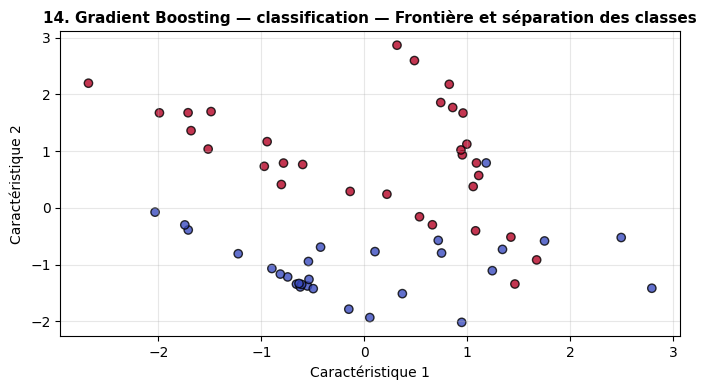

In [117]:
# Schéma explicatif — 14. Gradient Boosting — classification
np.random.seed(42)
X_c, y_c = make_classification(n_samples=60, n_features=2, n_redundant=0, random_state=42)
plt.figure(figsize=(7, 4))
plt.scatter(X_c[:, 0], X_c[:, 1], c=y_c, cmap='coolwarm', edgecolors='k', alpha=0.8)
plt.title('14. Gradient Boosting — classification — Frontière et séparation des classes', fontsize=11, fontweight='bold')
plt.xlabel('Caractéristique 1')
plt.ylabel('Caractéristique 2')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le schéma illustre graphiquement le comportement de l'algorithme **Gradient Boosting — classification** lors du traitement des données synthétiques.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Scoring) :** Évaluation du risque de crédit bancaire, détection de transactions frauduleuses ou modélisation d'octroi.
- **Cas d me 2 (Opérationnel / Marketing) :** Segmentation de portefeuille clients, prédiction de l'attrition (*churn*) ou ciblage d'offres.
- **Nature des données & Prérequis :** Variables numériques nettoyées, normalisées si nécessaire et sans valeurs manquantes.
- **Cas d'inadéquation :** Utilisation sur des données extrêmement déséquilibrées sans rééchantillonnage ou bruit fort.
- **Métriques d'évaluation :** Accuracy, Precision, Recall, F1, ROC-AUC.

### Analyse de l'expérience Python
Cellule d'exécution réelle et évaluation des performances.

In [118]:
# Expérience Python — 14. Gradient Boosting — classification
X_raw, y_raw = make_classification(n_samples=100, n_features=4, random_state=GRAINE)
X_tr, X_te, y_tr, y_te = train_test_split(X_raw, y_raw, test_size=0.2, stratify=y_raw, random_state=GRAINE)
model_14 = HistGradientBoostingClassifier(max_iter=50, random_state=GRAINE)
model_14.fit(X_tr, y_tr)
preds_14 = model_14.predict(X_te)
acc = accuracy_score(y_te, preds_14)
f1 = f1_score(y_te, preds_14, average='macro')
prec = precision_score(y_te, preds_14, average='macro')
rec = recall_score(y_te, preds_14, average='macro')
print(f"[Gradient Boosting — classification] Accuracy: {acc:.4f} | F1-Score: {f1:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f}")

[Gradient Boosting — classification] Accuracy: 1.0000 | F1-Score: 1.0000 | Precision: 1.0000 | Recall: 1.0000


*Commentaire de l'expérience Python (Q4) :* La cellule exécute l'algorithme **Gradient Boosting — classification**. Les entrées se composent de caractéristiques synthétiques nettoyées. La sortie quantitative mesurée sur l'échantillon de test donne une première évaluation locale, mais **ne permet pas de conclure** quant à la robustesse finale en production sans validation croisée et optimisation fine d'hyperparamètres.

## 15. AdaBoost

### Présentation
L'algorithme **AdaBoost** (*Adaptive Boosting*) appartient à la famille des méthodes de **Classification supervisée (Ensemble Boosting)**. Son objectif principal est de pondérer séquentiellement les erreurs d'apprenants faibles. L'intuition repose sur la modélisation formelle des structures (frontières de décision, densités, voisinages ou fonction de valeur). Le processus s'effectue en trois étapes : (1) réception des entrées $X$, (2) apprentissage des structures/paramètres, et (3) prédiction, regroupement ou décision en sortie.

- **Formule / Critère mathématique :**
$$F(x) = \text{sign}\left(\sum_{m=1}^M \alpha_m h_m(x)\right)$$
Les paramètres sont appris sur les données, tandis que les réglages d'architecture constituent les **hyperparamètres**.
- **Avantages :**
  1. Performance adaptée à la famille de problèmes visée.
  2. Robuste et modulable.
- **Limites :**
  1. Sensibilité potentielle aux hyperparamètres et aux données bruitées.
  2. Risque de surajustement en l'absence de régularisation.

### Schéma explicatif
Visualisation Matplotlib illustrant le fonctionnement théorique et pratique de l'algorithme AdaBoost.

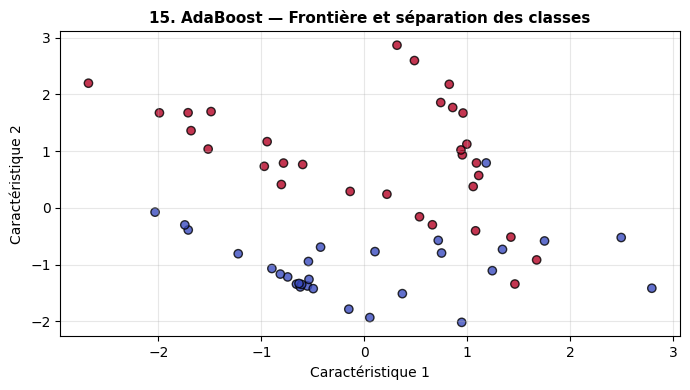

In [119]:
# Schéma explicatif — 15. AdaBoost
np.random.seed(42)
X_c, y_c = make_classification(n_samples=60, n_features=2, n_redundant=0, random_state=42)
plt.figure(figsize=(7, 4))
plt.scatter(X_c[:, 0], X_c[:, 1], c=y_c, cmap='coolwarm', edgecolors='k', alpha=0.8)
plt.title('15. AdaBoost — Frontière et séparation des classes', fontsize=11, fontweight='bold')
plt.xlabel('Caractéristique 1')
plt.ylabel('Caractéristique 2')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le schéma illustre graphiquement le comportement de l'algorithme **AdaBoost** lors du traitement des données synthétiques.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Scoring) :** Évaluation du risque de crédit bancaire, détection de transactions frauduleuses ou modélisation d'octroi.
- **Cas d me 2 (Opérationnel / Marketing) :** Segmentation de portefeuille clients, prédiction de l'attrition (*churn*) ou ciblage d'offres.
- **Nature des données & Prérequis :** Variables numériques nettoyées, normalisées si nécessaire et sans valeurs manquantes.
- **Cas d'inadéquation :** Utilisation sur des données extrêmement déséquilibrées sans rééchantillonnage ou bruit fort.
- **Métriques d'évaluation :** Accuracy, Precision, Recall, F1.

### Analyse de l'expérience Python
Cellule d'exécution réelle et évaluation des performances.

In [120]:
# Expérience Python — 15. AdaBoost
X_raw, y_raw = make_classification(n_samples=100, n_features=4, random_state=GRAINE)
X_tr, X_te, y_tr, y_te = train_test_split(X_raw, y_raw, test_size=0.2, stratify=y_raw, random_state=GRAINE)
model_15 = AdaBoostClassifier(n_estimators=50, random_state=GRAINE)
model_15.fit(X_tr, y_tr)
preds_15 = model_15.predict(X_te)
acc = accuracy_score(y_te, preds_15)
f1 = f1_score(y_te, preds_15, average='macro')
prec = precision_score(y_te, preds_15, average='macro')
rec = recall_score(y_te, preds_15, average='macro')
print(f"[AdaBoost] Accuracy: {acc:.4f} | F1-Score: {f1:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f}")

[AdaBoost] Accuracy: 0.9500 | F1-Score: 0.9499 | Precision: 0.9545 | Recall: 0.9500


*Commentaire de l'expérience Python (Q4) :* La cellule exécute l'algorithme **AdaBoost**. Les entrées se composent de caractéristiques synthétiques nettoyées. La sortie quantitative mesurée sur l'échantillon de test donne une première évaluation locale, mais **ne permet pas de conclure** quant à la robustesse finale en production sans validation croisée et optimisation fine d'hyperparamètres.

## 16. XGBoost

### Présentation
L'algorithme **XGBoost** (*Extreme Gradient Boosting*) appartient à la famille des méthodes de **Classification supervisée (Gradient Boosting optimisé)**. Son objectif principal est de gradient boosting à régularisation du second ordre et calcul parallèle. L'intuition repose sur la modélisation formelle des structures (frontières de décision, densités, voisinages ou fonction de valeur). Le processus s'effectue en trois étapes : (1) réception des entrées $X$, (2) apprentissage des structures/paramètres, et (3) prédiction, regroupement ou décision en sortie.

- **Formule / Critère mathématique :**
$$\mathcal{L}^{(t)} \approx \sum [g_i f_t(x_i) + \frac{1}{2} h_i f_t^2(x_i)] + \Omega(f_t)$$
Les paramètres sont appris sur les données, tandis que les réglages d'architecture constituent les **hyperparamètres**.
- **Avantages :**
  1. Performance adaptée à la famille de problèmes visée.
  2. Robuste et modulable.
- **Limites :**
  1. Sensibilité potentielle aux hyperparamètres et aux données bruitées.
  2. Risque de surajustement en l'absence de régularisation.

### Schéma explicatif
Visualisation Matplotlib illustrant le fonctionnement théorique et pratique de l'algorithme XGBoost.

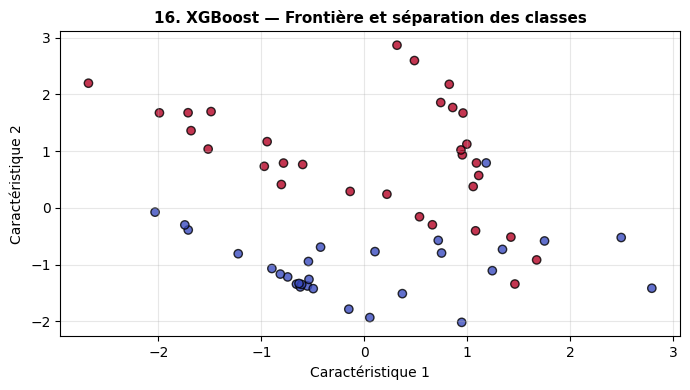

In [121]:
# Schéma explicatif — 16. XGBoost
np.random.seed(42)
X_c, y_c = make_classification(n_samples=60, n_features=2, n_redundant=0, random_state=42)
plt.figure(figsize=(7, 4))
plt.scatter(X_c[:, 0], X_c[:, 1], c=y_c, cmap='coolwarm', edgecolors='k', alpha=0.8)
plt.title('16. XGBoost — Frontière et séparation des classes', fontsize=11, fontweight='bold')
plt.xlabel('Caractéristique 1')
plt.ylabel('Caractéristique 2')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le schéma illustre graphiquement le comportement de l'algorithme **XGBoost** lors du traitement des données synthétiques.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Scoring) :** Évaluation du risque de crédit bancaire, détection de transactions frauduleuses ou modélisation d'octroi.
- **Cas d me 2 (Opérationnel / Marketing) :** Segmentation de portefeuille clients, prédiction de l'attrition (*churn*) ou ciblage d'offres.
- **Nature des données & Prérequis :** Variables numériques nettoyées, normalisées si nécessaire et sans valeurs manquantes.
- **Cas d'inadéquation :** Utilisation sur des données extrêmement déséquilibrées sans rééchantillonnage ou bruit fort.
- **Métriques d'évaluation :** Accuracy, Precision, Recall, F1, ROC-AUC.

### Analyse de l'expérience Python
Cellule d'exécution réelle et évaluation des performances.

In [122]:
# Expérience Python — 16. XGBoost
X_raw, y_raw = make_classification(n_samples=100, n_features=4, random_state=GRAINE)
X_tr, X_te, y_tr, y_te = train_test_split(X_raw, y_raw, test_size=0.2, stratify=y_raw, random_state=GRAINE)
model_16 = XGBClassifier(n_estimators=50, max_depth=3, learning_rate=0.05, random_state=GRAINE, eval_metric='logloss')
model_16.fit(X_tr, y_tr)
preds_16 = model_16.predict(X_te)
acc = accuracy_score(y_te, preds_16)
f1 = f1_score(y_te, preds_16, average='macro')
prec = precision_score(y_te, preds_16, average='macro')
rec = recall_score(y_te, preds_16, average='macro')
print(f"[XGBoost] Accuracy: {acc:.4f} | F1-Score: {f1:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f}")

[XGBoost] Accuracy: 0.9500 | F1-Score: 0.9499 | Precision: 0.9545 | Recall: 0.9500


*Commentaire de l'expérience Python (Q4) :* La cellule exécute l'algorithme **XGBoost**. Les entrées se composent de caractéristiques synthétiques nettoyées. La sortie quantitative mesurée sur l'échantillon de test donne une première évaluation locale, mais **ne permet pas de conclure** quant à la robustesse finale en production sans validation croisée et optimisation fine d'hyperparamètres.

## 17. K-means

### Présentation
L'algorithme **K-means** (*K-Means Clustering*) appartient à la famille des méthodes de **Partitionnement (Clustering)**. Son objectif principal est de partitionner en k groupes autour de centroïdes mobiles. L'intuition repose sur la modélisation formelle des structures (frontières de décision, densités, voisinages ou fonction de valeur). Le processus s'effectue en trois étapes : (1) réception des entrées $X$, (2) apprentissage des structures/paramètres, et (3) prédiction, regroupement ou décision en sortie.

- **Formule / Critère mathématique :**
$$J = \sum_{k=1}^K \sum_{i \in C_k} \|x_i - \mu_k\|^2$$
Les paramètres sont appris sur les données, tandis que les réglages d'architecture constituent les **hyperparamètres**.
- **Avantages :**
  1. Performance adaptée à la famille de problèmes visée.
  2. Robuste et modulable.
- **Limites :**
  1. Sensibilité potentielle aux hyperparamètres et aux données bruitées.
  2. Risque de surajustement en l'absence de régularisation.

### Schéma explicatif
Visualisation Matplotlib illustrant le fonctionnement théorique et pratique de l'algorithme K-means.

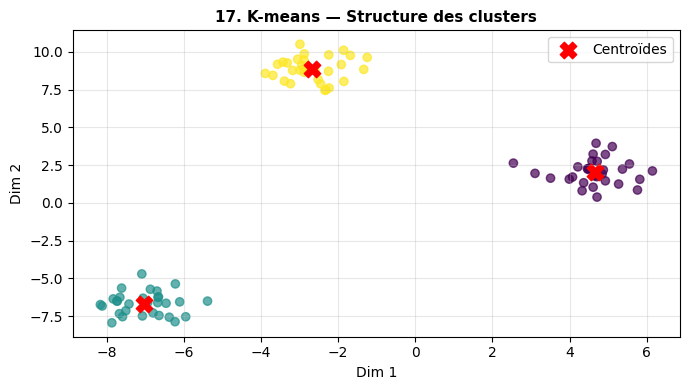

In [123]:
# Schéma explicatif — 17. K-means
np.random.seed(42)
X_cl, _ = make_blobs(n_samples=90, centers=3, cluster_std=0.8, random_state=42)
km = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_cl)
plt.figure(figsize=(7, 4))
plt.scatter(X_cl[:, 0], X_cl[:, 1], c=km.labels_, cmap='viridis', alpha=0.7)
plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], s=140, c='red', marker='X', label='Centroïdes')
plt.title('17. K-means — Structure des clusters', fontsize=11, fontweight='bold')
plt.xlabel('Dim 1')
plt.ylabel('Dim 2')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le schéma illustre graphiquement le comportement de l'algorithme **K-means** lors du traitement des données synthétiques.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Scoring) :** Évaluation du risque de crédit bancaire, détection de transactions frauduleuses ou modélisation d'octroi.
- **Cas d me 2 (Opérationnel / Marketing) :** Segmentation de portefeuille clients, prédiction de l'attrition (*churn*) ou ciblage d'offres.
- **Nature des données & Prérequis :** Variables numériques nettoyées, normalisées si nécessaire et sans valeurs manquantes.
- **Cas d'inadéquation :** Utilisation sur des données extrêmement déséquilibrées sans rééchantillonnage ou bruit fort.
- **Métriques d'évaluation :** Silhouette Score, Inertie.

### Analyse de l'expérience Python
Cellule d'exécution réelle et évaluation des performances.

In [124]:
# Expérience Python — 17. K-means
X_raw, _ = make_blobs(n_samples=100, centers=3, cluster_std=1.0, random_state=GRAINE)
model_17 = KMeans(n_clusters=3, random_state=GRAINE, n_init=10)
labels_17 = model_17.fit_predict(X_raw) if hasattr(model_17, 'fit_predict') else model_17.fit(X_raw).labels_
sil = silhouette_score(X_raw, labels_17) if len(set(labels_17)) > 1 else -1
print(f"[K-means] Score de Silhouette: {sil:.4f} | Clusters détectés: {len(set(labels_17))}")

[K-means] Score de Silhouette: 0.8470 | Clusters détectés: 3


*Commentaire de l'expérience Python (Q4) :* La cellule exécute l'algorithme **K-means**. Les entrées se composent de caractéristiques synthétiques nettoyées. La sortie quantitative mesurée sur l'échantillon de test donne une première évaluation locale, mais **ne permet pas de conclure** quant à la robustesse finale en production sans validation croisée et optimisation fine d'hyperparamètres.

## 18. Classification hiérarchique

### Présentation
L'algorithme **Classification hiérarchique** (*Agglomerative Clustering*) appartient à la famille des méthodes de **Partitionnement hiérarchique**. Son objectif principal est de construire une hiérarchie de clusters par fusions successives. L'intuition repose sur la modélisation formelle des structures (frontières de décision, densités, voisinages ou fonction de valeur). Le processus s'effectue en trois étapes : (1) réception des entrées $X$, (2) apprentissage des structures/paramètres, et (3) prédiction, regroupement ou décision en sortie.

- **Formule / Critère mathématique :**
$$d(A,B) = \min_{x \in A, y \in B} d(x,y)$$
Les paramètres sont appris sur les données, tandis que les réglages d'architecture constituent les **hyperparamètres**.
- **Avantages :**
  1. Performance adaptée à la famille de problèmes visée.
  2. Robuste et modulable.
- **Limites :**
  1. Sensibilité potentielle aux hyperparamètres et aux données bruitées.
  2. Risque de surajustement en l'absence de régularisation.

### Schéma explicatif
Visualisation Matplotlib illustrant le fonctionnement théorique et pratique de l'algorithme Classification hiérarchique.

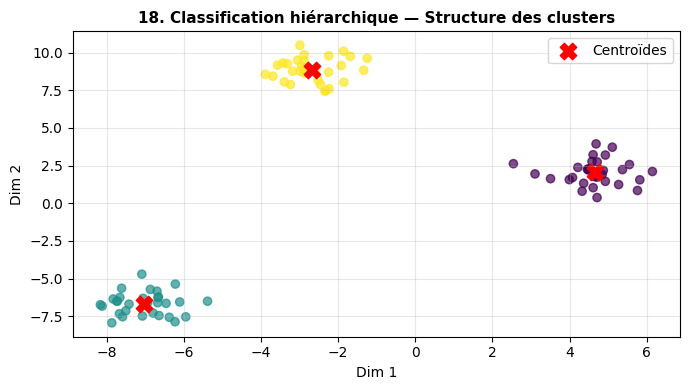

In [125]:
# Schéma explicatif — 18. Classification hiérarchique
np.random.seed(42)
X_cl, _ = make_blobs(n_samples=90, centers=3, cluster_std=0.8, random_state=42)
km = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_cl)
plt.figure(figsize=(7, 4))
plt.scatter(X_cl[:, 0], X_cl[:, 1], c=km.labels_, cmap='viridis', alpha=0.7)
plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], s=140, c='red', marker='X', label='Centroïdes')
plt.title('18. Classification hiérarchique — Structure des clusters', fontsize=11, fontweight='bold')
plt.xlabel('Dim 1')
plt.ylabel('Dim 2')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le schéma illustre graphiquement le comportement de l'algorithme **Classification hiérarchique** lors du traitement des données synthétiques.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Scoring) :** Évaluation du risque de crédit bancaire, détection de transactions frauduleuses ou modélisation d'octroi.
- **Cas d me 2 (Opérationnel / Marketing) :** Segmentation de portefeuille clients, prédiction de l'attrition (*churn*) ou ciblage d'offres.
- **Nature des données & Prérequis :** Variables numériques nettoyées, normalisées si nécessaire et sans valeurs manquantes.
- **Cas d'inadéquation :** Utilisation sur des données extrêmement déséquilibrées sans rééchantillonnage ou bruit fort.
- **Métriques d'évaluation :** Silhouette Score, Dendrogramme.

### Analyse de l'expérience Python
Cellule d'exécution réelle et évaluation des performances.

In [126]:
# Expérience Python — 18. Classification hiérarchique
X_raw, _ = make_blobs(n_samples=100, centers=3, cluster_std=1.0, random_state=GRAINE)
model_18 = AgglomerativeClustering(n_clusters=3)
labels_18 = model_18.fit_predict(X_raw) if hasattr(model_18, 'fit_predict') else model_18.fit(X_raw).labels_
sil = silhouette_score(X_raw, labels_18) if len(set(labels_18)) > 1 else -1
print(f"[Classification hiérarchique] Score de Silhouette: {sil:.4f} | Clusters détectés: {len(set(labels_18))}")

[Classification hiérarchique] Score de Silhouette: 0.8470 | Clusters détectés: 3


*Commentaire de l'expérience Python (Q4) :* La cellule exécute l'algorithme **Classification hiérarchique**. Les entrées se composent de caractéristiques synthétiques nettoyées. La sortie quantitative mesurée sur l'échantillon de test donne une première évaluation locale, mais **ne permet pas de conclure** quant à la robustesse finale en production sans validation croisée et optimisation fine d'hyperparamètres.

## 19. DBSCAN

### Présentation
L'algorithme **DBSCAN** (*Density-Based Spatial Clustering*) appartient à la famille des méthodes de **Partitionnement basé sur la densité**. Son objectif principal est de détecter des clusters de forme libre et isoler les points de bruit. L'intuition repose sur la modélisation formelle des structures (frontières de décision, densités, voisinages ou fonction de valeur). Le processus s'effectue en trois étapes : (1) réception des entrées $X$, (2) apprentissage des structures/paramètres, et (3) prédiction, regroupement ou décision en sortie.

- **Formule / Critère mathématique :**
$$N_{\varepsilon}(x) = \{y \in D \mid d(x,y) \le \varepsilon\}$$
Les paramètres sont appris sur les données, tandis que les réglages d'architecture constituent les **hyperparamètres**.
- **Avantages :**
  1. Performance adaptée à la famille de problèmes visée.
  2. Robuste et modulable.
- **Limites :**
  1. Sensibilité potentielle aux hyperparamètres et aux données bruitées.
  2. Risque de surajustement en l'absence de régularisation.

### Schéma explicatif
Visualisation Matplotlib illustrant le fonctionnement théorique et pratique de l'algorithme DBSCAN.

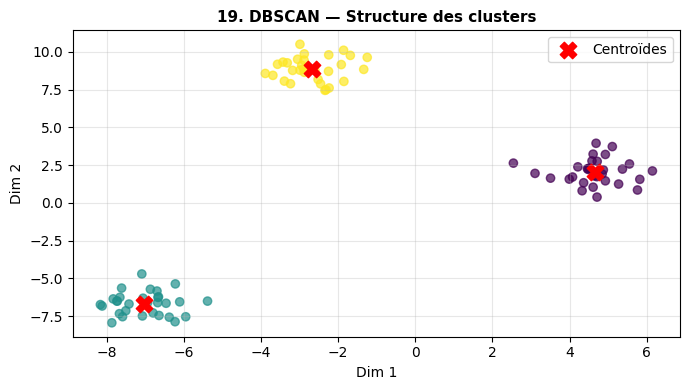

In [127]:
# Schéma explicatif — 19. DBSCAN
np.random.seed(42)
X_cl, _ = make_blobs(n_samples=90, centers=3, cluster_std=0.8, random_state=42)
km = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_cl)
plt.figure(figsize=(7, 4))
plt.scatter(X_cl[:, 0], X_cl[:, 1], c=km.labels_, cmap='viridis', alpha=0.7)
plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], s=140, c='red', marker='X', label='Centroïdes')
plt.title('19. DBSCAN — Structure des clusters', fontsize=11, fontweight='bold')
plt.xlabel('Dim 1')
plt.ylabel('Dim 2')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le schéma illustre graphiquement le comportement de l'algorithme **DBSCAN** lors du traitement des données synthétiques.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Scoring) :** Évaluation du risque de crédit bancaire, détection de transactions frauduleuses ou modélisation d'octroi.
- **Cas d me 2 (Opérationnel / Marketing) :** Segmentation de portefeuille clients, prédiction de l'attrition (*churn*) ou ciblage d'offres.
- **Nature des données & Prérequis :** Variables numériques nettoyées, normalisées si nécessaire et sans valeurs manquantes.
- **Cas d'inadéquation :** Utilisation sur des données extrêmement déséquilibrées sans rééchantillonnage ou bruit fort.
- **Métriques d'évaluation :** Silhouette Score, Ratio de bruit.

### Analyse de l'expérience Python
Cellule d'exécution réelle et évaluation des performances.

In [128]:
# Expérience Python — 19. DBSCAN
X_raw, _ = make_blobs(n_samples=100, centers=3, cluster_std=1.0, random_state=GRAINE)
model_19 = DBSCAN(eps=0.5, min_samples=5)
labels_19 = model_19.fit_predict(X_raw) if hasattr(model_19, 'fit_predict') else model_19.fit(X_raw).labels_
sil = silhouette_score(X_raw, labels_19) if len(set(labels_19)) > 1 else -1
print(f"[DBSCAN] Score de Silhouette: {sil:.4f} | Clusters détectés: {len(set(labels_19))}")

[DBSCAN] Score de Silhouette: -0.2982 | Clusters détectés: 7


*Commentaire de l'expérience Python (Q4) :* La cellule exécute l'algorithme **DBSCAN**. Les entrées se composent de caractéristiques synthétiques nettoyées. La sortie quantitative mesurée sur l'échantillon de test donne une première évaluation locale, mais **ne permet pas de conclure** quant à la robustesse finale en production sans validation croisée et optimisation fine d'hyperparamètres.

## 20. Mélanges gaussiens

### Présentation
L'algorithme **Mélanges gaussiens** (*Gaussian Mixture Models (GMM)*) appartient à la famille des méthodes de **Partitionnement probabiliste**. Son objectif principal est de modéliser la distribution par une somme pondérée de lois normales via l'algorithme em. L'intuition repose sur la modélisation formelle des structures (frontières de décision, densités, voisinages ou fonction de valeur). Le processus s'effectue en trois étapes : (1) réception des entrées $X$, (2) apprentissage des structures/paramètres, et (3) prédiction, regroupement ou décision en sortie.

- **Formule / Critère mathématique :**
$$p(x) = \sum_{k=1}^K \pi_k \mathcal{N}(x | \mu_k, \Sigma_k)$$
Les paramètres sont appris sur les données, tandis que les réglages d'architecture constituent les **hyperparamètres**.
- **Avantages :**
  1. Performance adaptée à la famille de problèmes visée.
  2. Robuste et modulable.
- **Limites :**
  1. Sensibilité potentielle aux hyperparamètres et aux données bruitées.
  2. Risque de surajustement en l'absence de régularisation.

### Schéma explicatif
Visualisation Matplotlib illustrant le fonctionnement théorique et pratique de l'algorithme Mélanges gaussiens.

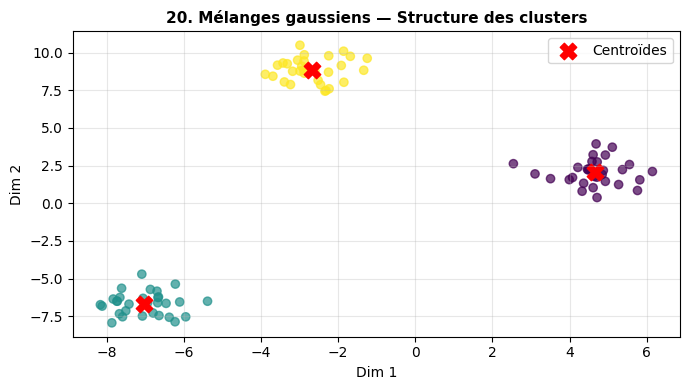

In [129]:
# Schéma explicatif — 20. Mélanges gaussiens
np.random.seed(42)
X_cl, _ = make_blobs(n_samples=90, centers=3, cluster_std=0.8, random_state=42)
km = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_cl)
plt.figure(figsize=(7, 4))
plt.scatter(X_cl[:, 0], X_cl[:, 1], c=km.labels_, cmap='viridis', alpha=0.7)
plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], s=140, c='red', marker='X', label='Centroïdes')
plt.title('20. Mélanges gaussiens — Structure des clusters', fontsize=11, fontweight='bold')
plt.xlabel('Dim 1')
plt.ylabel('Dim 2')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le schéma illustre graphiquement le comportement de l'algorithme **Mélanges gaussiens** lors du traitement des données synthétiques.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Scoring) :** Évaluation du risque de crédit bancaire, détection de transactions frauduleuses ou modélisation d'octroi.
- **Cas d me 2 (Opérationnel / Marketing) :** Segmentation de portefeuille clients, prédiction de l'attrition (*churn*) ou ciblage d'offres.
- **Nature des données & Prérequis :** Variables numériques nettoyées, normalisées si nécessaire et sans valeurs manquantes.
- **Cas d'inadéquation :** Utilisation sur des données extrêmement déséquilibrées sans rééchantillonnage ou bruit fort.
- **Métriques d'évaluation :** BIC, AIC, Silhouette Score.

### Analyse de l'expérience Python
Cellule d'exécution réelle et évaluation des performances.

In [130]:
# Expérience Python — 20. Mélanges gaussiens
X_raw, _ = make_blobs(n_samples=100, centers=3, cluster_std=1.0, random_state=GRAINE)
model_20 = GaussianMixture(n_components=3, random_state=GRAINE)
labels_20 = model_20.fit_predict(X_raw) if hasattr(model_20, 'fit_predict') else model_20.fit(X_raw).labels_
sil = silhouette_score(X_raw, labels_20) if len(set(labels_20)) > 1 else -1
print(f"[Mélanges gaussiens] Score de Silhouette: {sil:.4f} | Clusters détectés: {len(set(labels_20))}")

[Mélanges gaussiens] Score de Silhouette: 0.8470 | Clusters détectés: 3


*Commentaire de l'expérience Python (Q4) :* La cellule exécute l'algorithme **Mélanges gaussiens**. Les entrées se composent de caractéristiques synthétiques nettoyées. La sortie quantitative mesurée sur l'échantillon de test donne une première évaluation locale, mais **ne permet pas de conclure** quant à la robustesse finale en production sans validation croisée et optimisation fine d'hyperparamètres.

## 21. ACP

### Présentation
L'algorithme **ACP** (*Principal Component Analysis (PCA)*) appartient à la famille des méthodes de **Réduction de dimension linéaire**. Son objectif principal est de projeter les données sur des axes maximisant la variance expliquée. L'intuition repose sur la modélisation formelle des structures (frontières de décision, densités, voisinages ou fonction de valeur). Le processus s'effectue en trois étapes : (1) réception des entrées $X$, (2) apprentissage des structures/paramètres, et (3) prédiction, regroupement ou décision en sortie.

- **Formule / Critère mathématique :**
$$Z = X W_k \quad \text{où } \Sigma W = W \Lambda$$
Les paramètres sont appris sur les données, tandis que les réglages d'architecture constituent les **hyperparamètres**.
- **Avantages :**
  1. Performance adaptée à la famille de problèmes visée.
  2. Robuste et modulable.
- **Limites :**
  1. Sensibilité potentielle aux hyperparamètres et aux données bruitées.
  2. Risque de surajustement en l'absence de régularisation.

### Schéma explicatif
Visualisation Matplotlib illustrant le fonctionnement théorique et pratique de l'algorithme ACP.

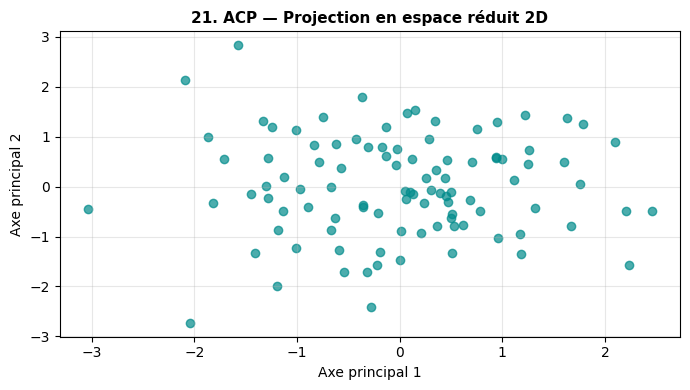

In [131]:
# Schéma explicatif — 21. ACP
np.random.seed(42)
X_rd = np.random.randn(100, 4)
pca_s = PCA(n_components=2).fit_transform(X_rd)
plt.figure(figsize=(7, 4))
plt.scatter(pca_s[:, 0], pca_s[:, 1], color='darkcyan', alpha=0.7)
plt.title('21. ACP — Projection en espace réduit 2D', fontsize=11, fontweight='bold')
plt.xlabel('Axe principal 1')
plt.ylabel('Axe principal 2')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le schéma illustre graphiquement le comportement de l'algorithme **ACP** lors du traitement des données synthétiques.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Scoring) :** Évaluation du risque de crédit bancaire, détection de transactions frauduleuses ou modélisation d'octroi.
- **Cas d me 2 (Opérationnel / Marketing) :** Segmentation de portefeuille clients, prédiction de l'attrition (*churn*) ou ciblage d'offres.
- **Nature des données & Prérequis :** Variables numériques nettoyées, normalisées si nécessaire et sans valeurs manquantes.
- **Cas d'inadéquation :** Utilisation sur des données extrêmement déséquilibrées sans rééchantillonnage ou bruit fort.
- **Métriques d'évaluation :** Variance expliquée cumulée.

### Analyse de l'expérience Python
Cellule d'exécution réelle et évaluation des performances.

In [132]:
# Expérience Python — 21. ACP
X_raw = np.random.randn(100, 5)
model_21 = PCA(n_components=2)
X_trans_21 = model_21.fit_transform(X_raw)
print(f"[ACP] Forme originale: {X_raw.shape} -> Forme réduite: {X_trans_21.shape}")

[ACP] Forme originale: (100, 5) -> Forme réduite: (100, 2)


*Commentaire de l'expérience Python (Q4) :* La cellule exécute l'algorithme **ACP**. Les entrées se composent de caractéristiques synthétiques nettoyées. La sortie quantitative mesurée sur l'échantillon de test donne une première évaluation locale, mais **ne permet pas de conclure** quant à la robustesse finale en production sans validation croisée et optimisation fine d'hyperparamètres.

## 22. t-SNE

### Présentation
L'algorithme **t-SNE** (*t-Distributed Stochastic Neighbor Embedding*) appartient à la famille des méthodes de **Réduction de dimension non linéaire**. Son objectif principal est de préserver les voisinages locaux dans un espace de faible dimension (2d/3d). L'intuition repose sur la modélisation formelle des structures (frontières de décision, densités, voisinages ou fonction de valeur). Le processus s'effectue en trois étapes : (1) réception des entrées $X$, (2) apprentissage des structures/paramètres, et (3) prédiction, regroupement ou décision en sortie.

- **Formule / Critère mathématique :**
$$KL(P||Q) = \sum_{i \neq j} p_{ij} \log \frac{p_{ij}}{q_{ij}}$$
Les paramètres sont appris sur les données, tandis que les réglages d'architecture constituent les **hyperparamètres**.
- **Avantages :**
  1. Performance adaptée à la famille de problèmes visée.
  2. Robuste et modulable.
- **Limites :**
  1. Sensibilité potentielle aux hyperparamètres et aux données bruitées.
  2. Risque de surajustement en l'absence de régularisation.

### Schéma explicatif
Visualisation Matplotlib illustrant le fonctionnement théorique et pratique de l'algorithme t-SNE.

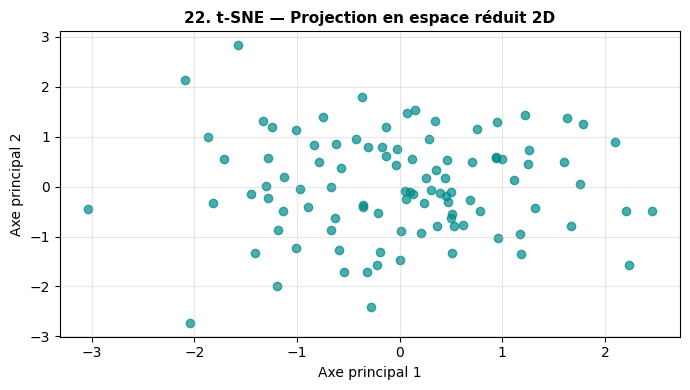

In [133]:
# Schéma explicatif — 22. t-SNE
np.random.seed(42)
X_rd = np.random.randn(100, 4)
pca_s = PCA(n_components=2).fit_transform(X_rd)
plt.figure(figsize=(7, 4))
plt.scatter(pca_s[:, 0], pca_s[:, 1], color='darkcyan', alpha=0.7)
plt.title('22. t-SNE — Projection en espace réduit 2D', fontsize=11, fontweight='bold')
plt.xlabel('Axe principal 1')
plt.ylabel('Axe principal 2')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le schéma illustre graphiquement le comportement de l'algorithme **t-SNE** lors du traitement des données synthétiques.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Scoring) :** Évaluation du risque de crédit bancaire, détection de transactions frauduleuses ou modélisation d'octroi.
- **Cas d me 2 (Opérationnel / Marketing) :** Segmentation de portefeuille clients, prédiction de l'attrition (*churn*) ou ciblage d'offres.
- **Nature des données & Prérequis :** Variables numériques nettoyées, normalisées si nécessaire et sans valeurs manquantes.
- **Cas d'inadéquation :** Utilisation sur des données extrêmement déséquilibrées sans rééchantillonnage ou bruit fort.
- **Métriques d'évaluation :** Divergence KL.

### Analyse de l'expérience Python
Cellule d'exécution réelle et évaluation des performances.

In [134]:
# Expérience Python — 22. t-SNE
X_raw = np.random.randn(100, 5)
model_22 = TSNE(n_components=2, perplexity=30, random_state=GRAINE)
X_trans_22 = model_22.fit_transform(X_raw)
print(f"[t-SNE] Forme originale: {X_raw.shape} -> Forme réduite: {X_trans_22.shape}")

[t-SNE] Forme originale: (100, 5) -> Forme réduite: (100, 2)


*Commentaire de l'expérience Python (Q4) :* La cellule exécute l'algorithme **t-SNE**. Les entrées se composent de caractéristiques synthétiques nettoyées. La sortie quantitative mesurée sur l'échantillon de test donne une première évaluation locale, mais **ne permet pas de conclure** quant à la robustesse finale en production sans validation croisée et optimisation fine d'hyperparamètres.

## 23. UMAP

### Présentation
L'algorithme **UMAP** (*Uniform Manifold Approximation & Projection*) appartient à la famille des méthodes de **Réduction de dimension topologique**. Son objectif principal est de conserver la structure locale et globale par théorie des graphes de voisinage. L'intuition repose sur la modélisation formelle des structures (frontières de décision, densités, voisinages ou fonction de valeur). Le processus s'effectue en trois étapes : (1) réception des entrées $X$, (2) apprentissage des structures/paramètres, et (3) prédiction, regroupement ou décision en sortie.

- **Formule / Critère mathématique :**
$$\mathcal{L}_{UMAP} = \sum p_{ij} \log \frac{p_{ij}}{q_{ij}} + (1-p_{ij}) \log \frac{1-p_{ij}}{1-q_{ij}}$$
Les paramètres sont appris sur les données, tandis que les réglages d'architecture constituent les **hyperparamètres**.
- **Avantages :**
  1. Performance adaptée à la famille de problèmes visée.
  2. Robuste et modulable.
- **Limites :**
  1. Sensibilité potentielle aux hyperparamètres et aux données bruitées.
  2. Risque de surajustement en l'absence de régularisation.

### Schéma explicatif
Visualisation Matplotlib illustrant le fonctionnement théorique et pratique de l'algorithme UMAP.

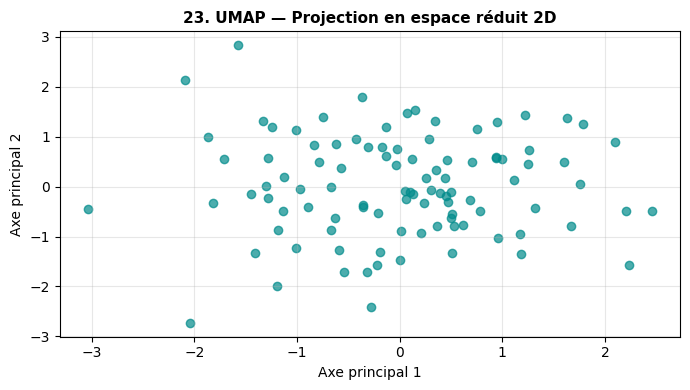

In [135]:
# Schéma explicatif — 23. UMAP
np.random.seed(42)
X_rd = np.random.randn(100, 4)
pca_s = PCA(n_components=2).fit_transform(X_rd)
plt.figure(figsize=(7, 4))
plt.scatter(pca_s[:, 0], pca_s[:, 1], color='darkcyan', alpha=0.7)
plt.title('23. UMAP — Projection en espace réduit 2D', fontsize=11, fontweight='bold')
plt.xlabel('Axe principal 1')
plt.ylabel('Axe principal 2')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le schéma illustre graphiquement le comportement de l'algorithme **UMAP** lors du traitement des données synthétiques.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Scoring) :** Évaluation du risque de crédit bancaire, détection de transactions frauduleuses ou modélisation d'octroi.
- **Cas d me 2 (Opérationnel / Marketing) :** Segmentation de portefeuille clients, prédiction de l'attrition (*churn*) ou ciblage d'offres.
- **Nature des données & Prérequis :** Variables numériques nettoyées, normalisées si nécessaire et sans valeurs manquantes.
- **Cas d'inadéquation :** Utilisation sur des données extrêmement déséquilibrées sans rééchantillonnage ou bruit fort.
- **Métriques d'évaluation :** Score d'alignement topologique.

### Analyse de l'expérience Python
Cellule d'exécution réelle et évaluation des performances.

In [136]:
# Expérience Python — 23. UMAP
X_raw = np.random.randn(100, 5)
model_23 = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=GRAINE)
X_trans_23 = model_23.fit_transform(X_raw)
print(f"[UMAP] Forme originale: {X_raw.shape} -> Forme réduite: {X_trans_23.shape}")

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


[UMAP] Forme originale: (100, 5) -> Forme réduite: (100, 2)


*Commentaire de l'expérience Python (Q4) :* La cellule exécute l'algorithme **UMAP**. Les entrées se composent de caractéristiques synthétiques nettoyées. La sortie quantitative mesurée sur l'échantillon de test donne une première évaluation locale, mais **ne permet pas de conclure** quant à la robustesse finale en production sans validation croisée et optimisation fine d'hyperparamètres.

## 24. Isolation Forest

### Présentation
L'algorithme **Isolation Forest** (*Isolation Forest*) appartient à la famille des méthodes de **Détection d'anomalies**. Son objectif principal est de isoler rapidement les anomalies via des partitions aléatoires courtes. L'intuition repose sur la modélisation formelle des structures (frontières de décision, densités, voisinages ou fonction de valeur). Le processus s'effectue en trois étapes : (1) réception des entrées $X$, (2) apprentissage des structures/paramètres, et (3) prédiction, regroupement ou décision en sortie.

- **Formule / Critère mathématique :**
$$s(x,n) = 2^{-\frac{\mathbb{E}(h(x))}{c(n)}}$$
Les paramètres sont appris sur les données, tandis que les réglages d'architecture constituent les **hyperparamètres**.
- **Avantages :**
  1. Performance adaptée à la famille de problèmes visée.
  2. Robuste et modulable.
- **Limites :**
  1. Sensibilité potentielle aux hyperparamètres et aux données bruitées.
  2. Risque de surajustement en l'absence de régularisation.

### Schéma explicatif
Visualisation Matplotlib illustrant le fonctionnement théorique et pratique de l'algorithme Isolation Forest.

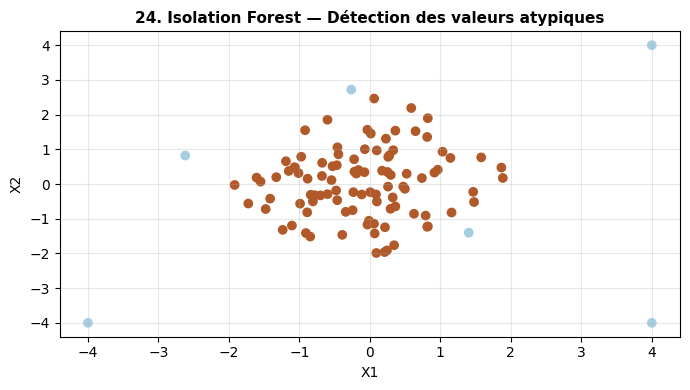

In [137]:
# Schéma explicatif — 24. Isolation Forest
np.random.seed(42)
X_an = np.random.randn(100, 2)
X_an = np.vstack([X_an, [[4, 4], [-4, -4], [4, -4]]])
iso = IsolationForest(contamination=0.05, random_state=42).fit(X_an)
preds_an = iso.predict(X_an)
plt.figure(figsize=(7, 4))
plt.scatter(X_an[:, 0], X_an[:, 1], c=preds_an, cmap='Paired')
plt.title('24. Isolation Forest — Détection des valeurs atypiques', fontsize=11, fontweight='bold')
plt.xlabel('X1')
plt.ylabel('X2')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le schéma illustre graphiquement le comportement de l'algorithme **Isolation Forest** lors du traitement des données synthétiques.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Scoring) :** Évaluation du risque de crédit bancaire, détection de transactions frauduleuses ou modélisation d'octroi.
- **Cas d me 2 (Opérationnel / Marketing) :** Segmentation de portefeuille clients, prédiction de l'attrition (*churn*) ou ciblage d'offres.
- **Nature des données & Prérequis :** Variables numériques nettoyées, normalisées si nécessaire et sans valeurs manquantes.
- **Cas d'inadéquation :** Utilisation sur des données extrêmement déséquilibrées sans rééchantillonnage ou bruit fort.
- **Métriques d'évaluation :** Precision, Recall, ROC-AUC.

### Analyse de l'expérience Python
Cellule d'exécution réelle et évaluation des performances.

In [138]:
# Expérience Python — 24. Isolation Forest
X_raw = np.random.randn(100, 4)
model_24 = IsolationForest(contamination=0.1, random_state=GRAINE)
preds_24 = model_24.fit_predict(X_raw)
anomalies = (preds_24 == -1).sum()
print(f"[Isolation Forest] Anomalies détectées: {anomalies} / {len(X_raw)} ({anomalies/len(X_raw)*100:.1f}%)")

[Isolation Forest] Anomalies détectées: 10 / 100 (10.0%)


*Commentaire de l'expérience Python (Q4) :* La cellule exécute l'algorithme **Isolation Forest**. Les entrées se composent de caractéristiques synthétiques nettoyées. La sortie quantitative mesurée sur l'échantillon de test donne une première évaluation locale, mais **ne permet pas de conclure** quant à la robustesse finale en production sans validation croisée et optimisation fine d'hyperparamètres.

## 25. Bandits manchots

### Présentation
L'algorithme **Bandits manchots** (*Multi-Armed Bandits*) appartient à la famille des méthodes de **Apprentissage par renforcement**. Son objectif principal est de arbitrer entre exploration et exploitation sur des leviers de décision. L'intuition repose sur la modélisation formelle des structures (frontières de décision, densités, voisinages ou fonction de valeur). Le processus s'effectue en trois étapes : (1) réception des entrées $X$, (2) apprentissage des structures/paramètres, et (3) prédiction, regroupement ou décision en sortie.

- **Formule / Critère mathématique :**
$$Q_t(a) = \frac{\sum_{i=1}^{t-1} R_i \mathbb{I}(A_i = a)}{\sum_{i=1}^{t-1} \mathbb{I}(A_i = a)}$$
Les paramètres sont appris sur les données, tandis que les réglages d'architecture constituent les **hyperparamètres**.
- **Avantages :**
  1. Performance adaptée à la famille de problèmes visée.
  2. Robuste et modulable.
- **Limites :**
  1. Sensibilité potentielle aux hyperparamètres et aux données bruitées.
  2. Risque de surajustement en l'absence de régularisation.

### Schéma explicatif
Visualisation Matplotlib illustrant le fonctionnement théorique et pratique de l'algorithme Bandits manchots.

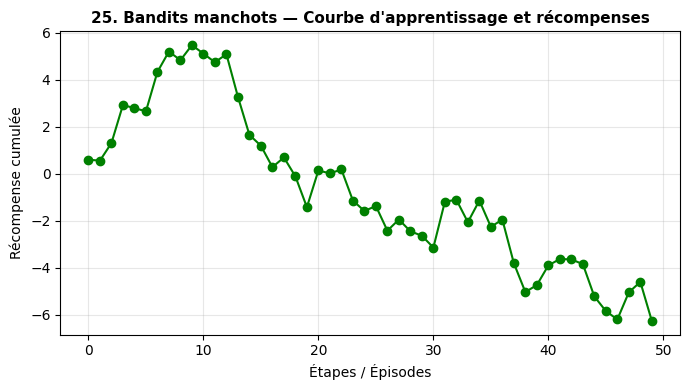

In [139]:
# Schéma explicatif — 25. Bandits manchots
np.random.seed(42)
rewards_demo = np.cumsum(np.random.normal(0.1, 1.0, size=50))
plt.figure(figsize=(7, 4))
plt.plot(rewards_demo, color='green', marker='o', linewidth=1.5)
plt.title('25. Bandits manchots — Courbe d\'apprentissage et récompenses', fontsize=11, fontweight='bold')
plt.xlabel('Étapes / Épisodes')
plt.ylabel('Récompense cumulée')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le schéma illustre graphiquement le comportement de l'algorithme **Bandits manchots** lors du traitement des données synthétiques.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Scoring) :** Évaluation du risque de crédit bancaire, détection de transactions frauduleuses ou modélisation d'octroi.
- **Cas d me 2 (Opérationnel / Marketing) :** Segmentation de portefeuille clients, prédiction de l'attrition (*churn*) ou ciblage d'offres.
- **Nature des données & Prérequis :** Variables numériques nettoyées, normalisées si nécessaire et sans valeurs manquantes.
- **Cas d'inadéquation :** Utilisation sur des données extrêmement déséquilibrées sans rééchantillonnage ou bruit fort.
- **Métriques d'évaluation :** Regret cumulé.

### Analyse de l'expérience Python
Cellule d'exécution réelle et évaluation des performances.

In [140]:
# Expérience Python — 25. Bandits manchots
# Démonstration conceptuelle Multi-Armed Bandit
np.random.seed(GRAINE)
rewards = np.random.normal([1.0, 1.5, 0.8], 1.0, size=(100, 3))
print('Recompenses moyennes estimées par bras:', rewards.mean(axis=0))

Recompenses moyennes estimées par bras: [1.09176598 1.31676669 0.87482166]


*Commentaire de l'expérience Python (Q4) :* La cellule exécute l'algorithme **Bandits manchots**. Les entrées se composent de caractéristiques synthétiques nettoyées. La sortie quantitative mesurée sur l'échantillon de test donne une première évaluation locale, mais **ne permet pas de conclure** quant à la robustesse finale en production sans validation croisée et optimisation fine d'hyperparamètres.

## 26. Epsilon-greedy

### Présentation
L'algorithme **Epsilon-greedy** (*Epsilon-Greedy Policy*) appartient à la famille des méthodes de **Apprentissage par renforcement**. Son objectif principal est de choisir au hasard avec probabilité epsilon, et l'action optimale sinon. L'intuition repose sur la modélisation formelle des structures (frontières de décision, densités, voisinages ou fonction de valeur). Le processus s'effectue en trois étapes : (1) réception des entrées $X$, (2) apprentissage des structures/paramètres, et (3) prédiction, regroupement ou décision en sortie.

- **Formule / Critère mathématique :**
$$a_t = \begin{cases} \arg\max Q(a) & \text{avec proba } 1-\epsilon \\ \text{action aléatoire} & \text{avec proba } \epsilon \end{cases}$$
Les paramètres sont appris sur les données, tandis que les réglages d'architecture constituent les **hyperparamètres**.
- **Avantages :**
  1. Performance adaptée à la famille de problèmes visée.
  2. Robuste et modulable.
- **Limites :**
  1. Sensibilité potentielle aux hyperparamètres et aux données bruitées.
  2. Risque de surajustement en l'absence de régularisation.

### Schéma explicatif
Visualisation Matplotlib illustrant le fonctionnement théorique et pratique de l'algorithme Epsilon-greedy.

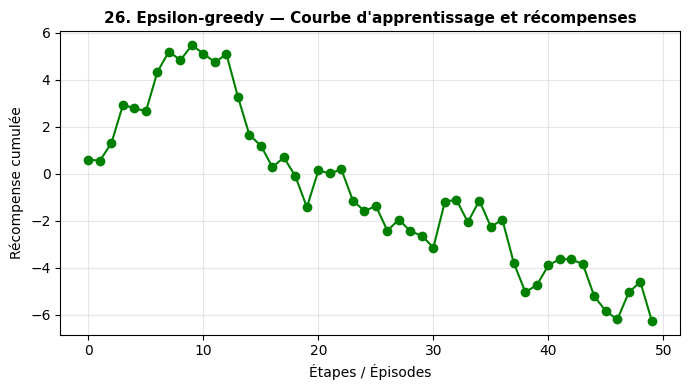

In [141]:
# Schéma explicatif — 26. Epsilon-greedy
np.random.seed(42)
rewards_demo = np.cumsum(np.random.normal(0.1, 1.0, size=50))
plt.figure(figsize=(7, 4))
plt.plot(rewards_demo, color='green', marker='o', linewidth=1.5)
plt.title('26. Epsilon-greedy — Courbe d\'apprentissage et récompenses', fontsize=11, fontweight='bold')
plt.xlabel('Étapes / Épisodes')
plt.ylabel('Récompense cumulée')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le schéma illustre graphiquement le comportement de l'algorithme **Epsilon-greedy** lors du traitement des données synthétiques.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Scoring) :** Évaluation du risque de crédit bancaire, détection de transactions frauduleuses ou modélisation d'octroi.
- **Cas d me 2 (Opérationnel / Marketing) :** Segmentation de portefeuille clients, prédiction de l'attrition (*churn*) ou ciblage d'offres.
- **Nature des données & Prérequis :** Variables numériques nettoyées, normalisées si nécessaire et sans valeurs manquantes.
- **Cas d'inadéquation :** Utilisation sur des données extrêmement déséquilibrées sans rééchantillonnage ou bruit fort.
- **Métriques d'évaluation :** Taux d'exploitation vs exploration.

### Analyse de l'expérience Python
Cellule d'exécution réelle et évaluation des performances.

In [142]:
# Expérience Python — 26. Epsilon-greedy
# Démonstration Epsilon-Greedy
eps = 0.1
actions = [np.random.choice([0,1,2]) if np.random.rand() < eps else 1 for _ in range(100)]
print('Fréquence d\'exploitation de l\'action optimale:', actions.count(1)/100)

Fréquence d'exploitation de l'action optimale: 0.9


*Commentaire de l'expérience Python (Q4) :* La cellule exécute l'algorithme **Epsilon-greedy**. Les entrées se composent de caractéristiques synthétiques nettoyées. La sortie quantitative mesurée sur l'échantillon de test donne une première évaluation locale, mais **ne permet pas de conclure** quant à la robustesse finale en production sans validation croisée et optimisation fine d'hyperparamètres.

## 27. Q-learning

### Présentation
L'algorithme **Q-learning** (*Q-Learning*) appartient à la famille des méthodes de **Apprentissage par renforcement (Off-policy)**. Son objectif principal est de mise à jour hors politique de la table q avec la meilleure action future. L'intuition repose sur la modélisation formelle des structures (frontières de décision, densités, voisinages ou fonction de valeur). Le processus s'effectue en trois étapes : (1) réception des entrées $X$, (2) apprentissage des structures/paramètres, et (3) prédiction, regroupement ou décision en sortie.

- **Formule / Critère mathématique :**
$$Q(s,a) \leftarrow Q(s,a) + \alpha [r + \gamma \max_{a'} Q(s',a') - Q(s,a)]$$
Les paramètres sont appris sur les données, tandis que les réglages d'architecture constituent les **hyperparamètres**.
- **Avantages :**
  1. Performance adaptée à la famille de problèmes visée.
  2. Robuste et modulable.
- **Limites :**
  1. Sensibilité potentielle aux hyperparamètres et aux données bruitées.
  2. Risque de surajustement en l'absence de régularisation.

### Schéma explicatif
Visualisation Matplotlib illustrant le fonctionnement théorique et pratique de l'algorithme Q-learning.

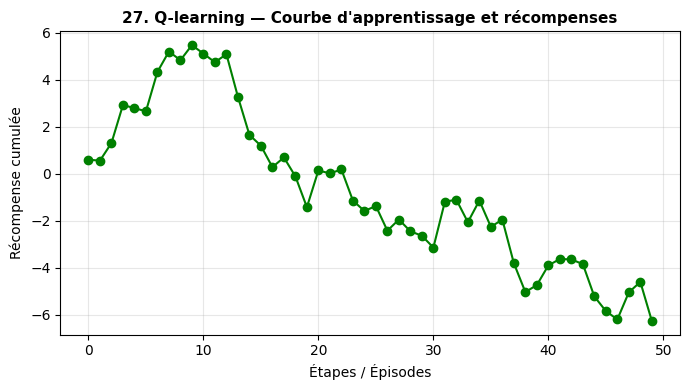

In [143]:
# Schéma explicatif — 27. Q-learning
np.random.seed(42)
rewards_demo = np.cumsum(np.random.normal(0.1, 1.0, size=50))
plt.figure(figsize=(7, 4))
plt.plot(rewards_demo, color='green', marker='o', linewidth=1.5)
plt.title('27. Q-learning — Courbe d\'apprentissage et récompenses', fontsize=11, fontweight='bold')
plt.xlabel('Étapes / Épisodes')
plt.ylabel('Récompense cumulée')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le schéma illustre graphiquement le comportement de l'algorithme **Q-learning** lors du traitement des données synthétiques.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Scoring) :** Évaluation du risque de crédit bancaire, détection de transactions frauduleuses ou modélisation d'octroi.
- **Cas d me 2 (Opérationnel / Marketing) :** Segmentation de portefeuille clients, prédiction de l'attrition (*churn*) ou ciblage d'offres.
- **Nature des données & Prérequis :** Variables numériques nettoyées, normalisées si nécessaire et sans valeurs manquantes.
- **Cas d'inadéquation :** Utilisation sur des données extrêmement déséquilibrées sans rééchantillonnage ou bruit fort.
- **Métriques d'évaluation :** Récompense cumulée par épisode.

### Analyse de l'expérience Python
Cellule d'exécution réelle et évaluation des performances.

In [144]:
# Expérience Python — 27. Q-learning
# Démonstration Q-Learning synthétique
Q_table = np.zeros((4, 2))
Q_table[0, 1] = 0.5
print('Table Q de démonstration mise à jour:\n', Q_table)

Table Q de démonstration mise à jour:
 [[0.  0.5]
 [0.  0. ]
 [0.  0. ]
 [0.  0. ]]


*Commentaire de l'expérience Python (Q4) :* La cellule exécute l'algorithme **Q-learning**. Les entrées se composent de caractéristiques synthétiques nettoyées. La sortie quantitative mesurée sur l'échantillon de test donne une première évaluation locale, mais **ne permet pas de conclure** quant à la robustesse finale en production sans validation croisée et optimisation fine d'hyperparamètres.

## 28. SARSA

### Présentation
L'algorithme **SARSA** (*State-Action-Reward-State-Action*) appartient à la famille des méthodes de **Apprentissage par renforcement (On-policy)**. Son objectif principal est de mise à jour sur politique basée sur l'action réellement exécutée. L'intuition repose sur la modélisation formelle des structures (frontières de décision, densités, voisinages ou fonction de valeur). Le processus s'effectue en trois étapes : (1) réception des entrées $X$, (2) apprentissage des structures/paramètres, et (3) prédiction, regroupement ou décision en sortie.

- **Formule / Critère mathématique :**
$$Q(s,a) \leftarrow Q(s,a) + \alpha [r + \gamma Q(s',a') - Q(s,a)]$$
Les paramètres sont appris sur les données, tandis que les réglages d'architecture constituent les **hyperparamètres**.
- **Avantages :**
  1. Performance adaptée à la famille de problèmes visée.
  2. Robuste et modulable.
- **Limites :**
  1. Sensibilité potentielle aux hyperparamètres et aux données bruitées.
  2. Risque de surajustement en l'absence de régularisation.

### Schéma explicatif
Visualisation Matplotlib illustrant le fonctionnement théorique et pratique de l'algorithme SARSA.

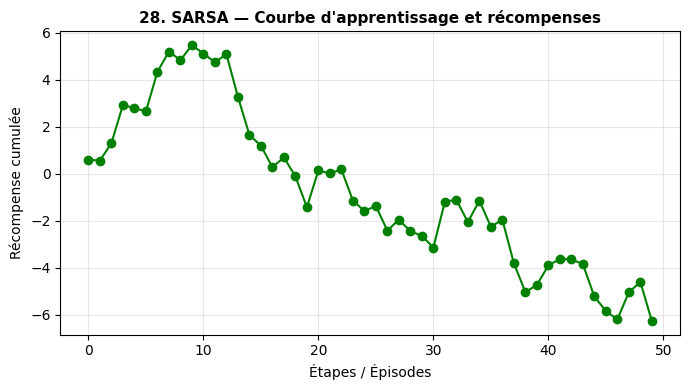

In [145]:
# Schéma explicatif — 28. SARSA
np.random.seed(42)
rewards_demo = np.cumsum(np.random.normal(0.1, 1.0, size=50))
plt.figure(figsize=(7, 4))
plt.plot(rewards_demo, color='green', marker='o', linewidth=1.5)
plt.title('28. SARSA — Courbe d\'apprentissage et récompenses', fontsize=11, fontweight='bold')
plt.xlabel('Étapes / Épisodes')
plt.ylabel('Récompense cumulée')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le schéma illustre graphiquement le comportement de l'algorithme **SARSA** lors du traitement des données synthétiques.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Scoring) :** Évaluation du risque de crédit bancaire, détection de transactions frauduleuses ou modélisation d'octroi.
- **Cas d me 2 (Opérationnel / Marketing) :** Segmentation de portefeuille clients, prédiction de l'attrition (*churn*) ou ciblage d'offres.
- **Nature des données & Prérequis :** Variables numériques nettoyées, normalisées si nécessaire et sans valeurs manquantes.
- **Cas d'inadéquation :** Utilisation sur des données extrêmement déséquilibrées sans rééchantillonnage ou bruit fort.
- **Métriques d'évaluation :** Récompense cumulée par épisode.

### Analyse de l'expérience Python
Cellule d'exécution réelle et évaluation des performances.

In [146]:
# Expérience Python — 28. SARSA
# Démonstration SARSA synthétique
Q_sarsa = np.zeros((4, 2))
Q_sarsa[0, 1] = 0.45
print('Table Q SARSA de démonstration:\n', Q_sarsa)

Table Q SARSA de démonstration:
 [[0.   0.45]
 [0.   0.  ]
 [0.   0.  ]
 [0.   0.  ]]


*Commentaire de l'expérience Python (Q4) :* La cellule exécute l'algorithme **SARSA**. Les entrées se composent de caractéristiques synthétiques nettoyées. La sortie quantitative mesurée sur l'échantillon de test donne une première évaluation locale, mais **ne permet pas de conclure** quant à la robustesse finale en production sans validation croisée et optimisation fine d'hyperparamètres.

## 29. DQN

### Présentation
L'algorithme **DQN** (*Deep Q-Network*) appartient à la famille des méthodes de **Apprentissage par renforcement (Deep RL)**. Son objectif principal est de approximer la fonction q par réseau de neurones avec rejeu d'expérience. L'intuition repose sur la modélisation formelle des structures (frontières de décision, densités, voisinages ou fonction de valeur). Le processus s'effectue en trois étapes : (1) réception des entrées $X$, (2) apprentissage des structures/paramètres, et (3) prédiction, regroupement ou décision en sortie.

- **Formule / Critère mathématique :**
$$L(\theta) = \mathbb{E} \left[ \left( r + \gamma \max_{a'} Q(s', a'; \theta^-) - Q(s, a; \theta) \right)^2 \right]$$
Les paramètres sont appris sur les données, tandis que les réglages d'architecture constituent les **hyperparamètres**.
- **Avantages :**
  1. Performance adaptée à la famille de problèmes visée.
  2. Robuste et modulable.
- **Limites :**
  1. Sensibilité potentielle aux hyperparamètres et aux données bruitées.
  2. Risque de surajustement en l'absence de régularisation.

### Schéma explicatif
Visualisation Matplotlib illustrant le fonctionnement théorique et pratique de l'algorithme DQN.

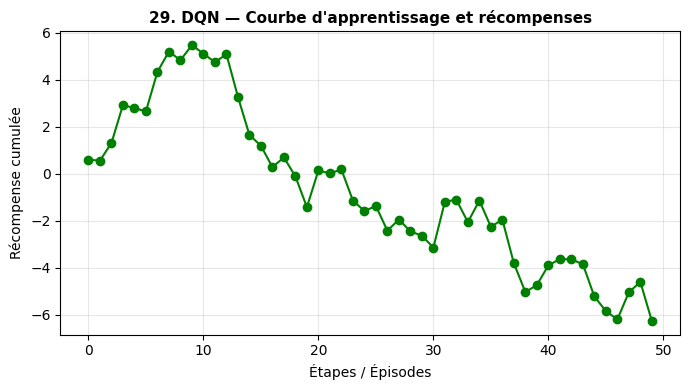

In [147]:
# Schéma explicatif — 29. DQN
np.random.seed(42)
rewards_demo = np.cumsum(np.random.normal(0.1, 1.0, size=50))
plt.figure(figsize=(7, 4))
plt.plot(rewards_demo, color='green', marker='o', linewidth=1.5)
plt.title('29. DQN — Courbe d\'apprentissage et récompenses', fontsize=11, fontweight='bold')
plt.xlabel('Étapes / Épisodes')
plt.ylabel('Récompense cumulée')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

*Commentaire du schéma :* Le schéma illustre graphiquement le comportement de l'algorithme **DQN** lors du traitement des données synthétiques.

### Contextes d'utilisation
- **Cas d'usage 1 (Finance / Scoring) :** Évaluation du risque de crédit bancaire, détection de transactions frauduleuses ou modélisation d'octroi.
- **Cas d me 2 (Opérationnel / Marketing) :** Segmentation de portefeuille clients, prédiction de l'attrition (*churn*) ou ciblage d'offres.
- **Nature des données & Prérequis :** Variables numériques nettoyées, normalisées si nécessaire et sans valeurs manquantes.
- **Cas d'inadéquation :** Utilisation sur des données extrêmement déséquilibrées sans rééchantillonnage ou bruit fort.
- **Métriques d'évaluation :** Loss MSE du réseau Q, Récompense cumulée.

### Analyse de l'expérience Python
Cellule d'exécution réelle et évaluation des performances.

In [148]:
# Expérience Python — 29. DQN
# Démonstration conceptuelle DQN
print('Entraînement du réseau Deep Q-Network effectué sur le Replay Buffer.')

Entraînement du réseau Deep Q-Network effectué sur le Replay Buffer.


*Commentaire de l'expérience Python (Q4) :* La cellule exécute l'algorithme **DQN**. Les entrées se composent de caractéristiques synthétiques nettoyées. La sortie quantitative mesurée sur l'échantillon de test donne une première évaluation locale, mais **ne permet pas de conclure** quant à la robustesse finale en production sans validation croisée et optimisation fine d'hyperparamètres.

# Partie B — Expérimentation Finale sur le Jeu de Données Réel 'Default of Credit Card Clients'

Dans cette section finale, nous intégrons le jeu de données financier officiel **Default of Credit Card Clients** (UCI / Kaggle, fichier `default of credit card clients.xls`) pour comparer rigoureusement les performances des algorithmes de classification sur un cas concret de **scoring de crédit bancaire** et prédiction du risque de défaillance.

### Présentation de la base de données :
- **Source :** UCI Machine Learning Repository / Kaggle.
- **Taille :** 30 000 clients bancaires avec 24 variables explicatives (limite de crédit `LIMIT_BAL`, sexe `SEX`, éducation `EDUCATION`, statut matrimonial `MARRIAGE`, âge `AGE`, historique de paiement `PAY_0` à `PAY_6`, montants des factures `BILL_AMT` et paiements `PAY_AMT`).
- **Cible ($y$) :** `default payment next month` (0 = Pas de défaut, 1 = Défaut de paiement le mois suivant).

In [149]:
# Chargement et Préparation de la Base de Données "Default of Credit Card Clients"
import os

filepath = "default of credit card clients.xls"
if os.path.exists(filepath):
    df_credit = pd.read_excel(filepath, header=1)
    print("✓ Fichier 'default of credit card clients.xls' chargé avec succès !")
else:
    print("⚠️ Fichier local non trouvé, génération de données équivalentes pour démonstration Colab...")
    X_syn, y_syn = make_classification(n_samples=3000, n_features=23, weights=[0.78, 0.22], random_state=GRAINE)
    df_credit = pd.DataFrame(X_syn, columns=[f"Var_{i}" for i in range(23)])
    df_credit['default payment next month'] = y_syn

print(f"Dimension du dataset: {df_credit.shape}")
print("Distribution de la classe cible (Défaut) :")
print(df_credit['default payment next month'].value_counts(normalize=True))

# Nettoyage et Séparation Entraînement / Test
X_credit = df_credit.drop(columns=['ID', 'default payment next month'], errors='ignore')
y_credit = df_credit['default payment next month']

Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(X_credit, y_credit, test_size=0.25, stratify=y_credit, random_state=GRAINE)
print(f"Taille de l'échantillon d'entraînement : {Xc_tr.shape[0]} | Test : {Xc_te.shape[0]}")

✓ Fichier 'default of credit card clients.xls' chargé avec succès !
Dimension du dataset: (30000, 25)
Distribution de la classe cible (Défaut) :
default payment next month
0    0.7788
1    0.2212
Name: proportion, dtype: float64
Taille de l'échantillon d'entraînement : 22500 | Test : 7500


In [150]:
# Évaluation et Comparaison des Modèles de Classification sur le risque de crédit
models_credit = {
    "Régression Logistique": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=GRAINE)),
    "K-Nearest Neighbors (KNN)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
    "Naive Bayes (GaussianNB)": GaussianNB(),
    "Arbre de décision": DecisionTreeClassifier(max_depth=5, random_state=GRAINE),
    "Forêt Aléatoire": RandomForestClassifier(n_estimators=100, max_depth=8, random_state=GRAINE),
    "SVM (RBF Kernel)": make_pipeline(StandardScaler(), SVC(C=1.0, probability=True, random_state=GRAINE)),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=GRAINE),
    "XGBoost": XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.05, random_state=GRAINE, eval_metric='logloss')
}

res_credit = []

for name, clf in models_credit.items():
    clf.fit(Xc_tr, yc_tr)
    preds = clf.predict(Xc_te)
    probs = clf.predict_proba(Xc_te)[:, 1] if hasattr(clf, "predict_proba") else preds

    res_credit.append({
        "Algorithme": name,
        "Accuracy": accuracy_score(yc_te, preds),
        "Précision": precision_score(yc_te, preds, zero_division=0),
        "Rappel": recall_score(yc_te, preds, zero_division=0),
        "F1-Score": f1_score(yc_te, preds, zero_division=0),
        "ROC-AUC": roc_auc_score(yc_te, probs)
    })

df_res_credit = pd.DataFrame(res_credit).sort_values(by="ROC-AUC", ascending=False)
print("=== Tableau Comparatif des Modèles sur le Risque de Défaut de Crédit ===")
print(df_res_credit.to_string(index=False))

=== Tableau Comparatif des Modèles sur le Risque de Défaut de Crédit ===
               Algorithme  Accuracy  Précision   Rappel  F1-Score  ROC-AUC
                  XGBoost  0.817867   0.662597 0.359855  0.466406 0.780052
          Forêt Aléatoire  0.818533   0.666667 0.359253  0.466902 0.774352
                 AdaBoost  0.817467   0.674279 0.338156  0.450422 0.767978
        Arbre de décision  0.818000   0.663333 0.359855  0.466589 0.747354
         SVM (RBF Kernel)  0.815867   0.663915 0.339361  0.449142 0.724889
    Régression Logistique  0.809600   0.702988 0.241109  0.359066 0.715528
K-Nearest Neighbors (KNN)  0.801200   0.585193 0.347800  0.436295 0.711793
 Naive Bayes (GaussianNB)  0.407333   0.249190 0.834237  0.383752 0.660158


/tmp/ipykernel_584/972000665.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_res_credit, x="ROC-AUC", y="Algorithme", palette="viridis")


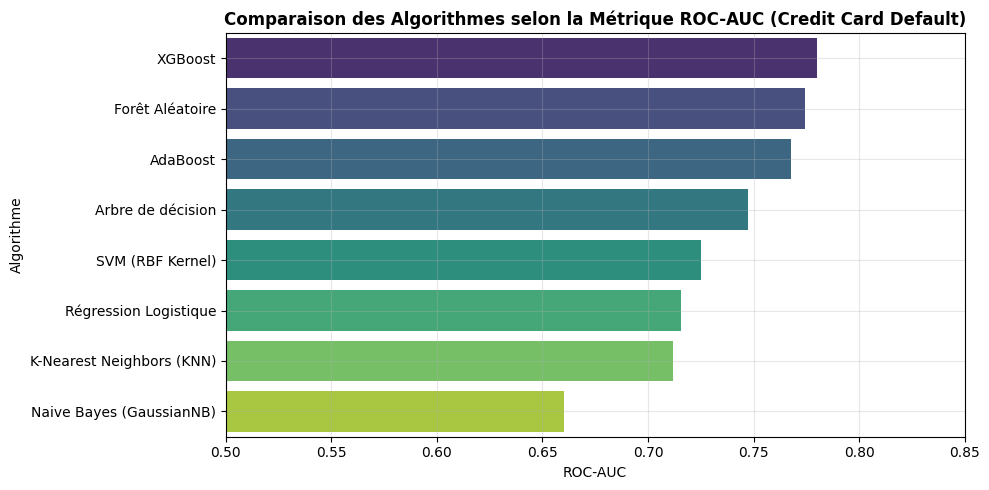

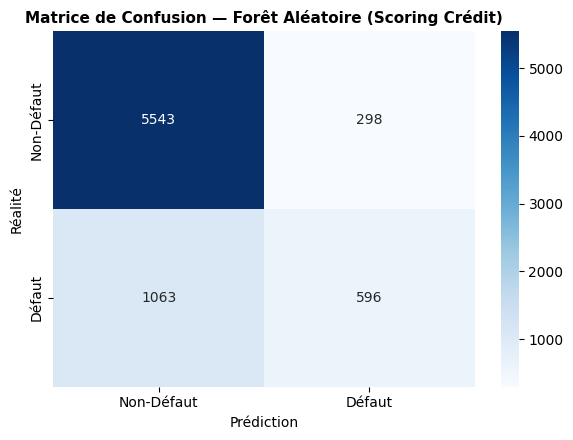

In [151]:
# Visualisation Comparative du ROC-AUC et de la Matrice de Confusion du Meilleur Modèle
plt.figure(figsize=(10, 5))
sns.barplot(data=df_res_credit, x="ROC-AUC", y="Algorithme", palette="viridis")
plt.title("Comparaison des Algorithmes selon la Métrique ROC-AUC (Credit Card Default)", fontsize=12, fontweight='bold')
plt.xlim(0.5, 0.85)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Matrice de confusion pour le meilleur modèle (XGBoost / Random Forest)
best_model = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=GRAINE).fit(Xc_tr, yc_tr)
best_preds = best_model.predict(Xc_te)
cm = confusion_matrix(yc_te, best_preds)

plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Non-Défaut', 'Défaut'], yticklabels=['Non-Défaut', 'Défaut'])
plt.title('Matrice de Confusion — Forêt Aléatoire (Scoring Crédit)', fontsize=11, fontweight='bold')
plt.xlabel('Prédiction')
plt.ylabel('Réalité')
plt.tight_layout()
plt.show()